# Chapter 4: Robust Beamforming that Minimizes Bit-Error-Rate Directly

Companion code for *Robust Adaptive Beamforming and Its Applications* by Ayman Elnashar (Wiley, forthcoming).

This notebook reproduces every simulation figure of Chapter 4 (Figures 4.1–4.11) and the numbers quoted in the text. The chapter develops **guided R-MBER**, a blind beamformer that needs no training symbols: a spectral guide estimates the source direction from the Capon spectrum, reconstructs the interference-plus-noise covariance outside a sector around it and forms a starting weight; a smoothed-BER step on the beamformer's own decisions then refines that weight, with the step scaled by the inverse of the reconstructed covariance (4.11). It is compared with WC-MVDR/EigDec, INCM-REC, SPSS, the constraint-based R-MBER in its blind and trained forms, and a training-aided Wiener filter (TA-MMSE).

A run counts as failed when its SINR is more than 3 dB below the optimum on the same block. Every Monte Carlo trial has a fixed seed, so every number can be regenerated exactly; only the runtime of Figure 4.1 depends on the machine.

## Configuration

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))   # chapter folder, so that `ch4rmber` imports without installation
QUICK = False             # True: at most two Monte Carlo trials per point (smoke test)
REUSE_DATA = True         # True: reuse the simulation data in FIGDIR/data when it is complete (e.g. written by scripts/generate_figures.py)
LOCAL_TIMING = False      # True: time this machine for Figure 4.1 instead of using the recorded run
FIGDIR = os.path.abspath('../figures')
os.environ.update(FIGDIR=FIGDIR, RAB_INLINE='1', RAB_LOCAL_TIMING='1' if LOCAL_TIMING else '0')
%matplotlib inline
from ch4rmber import scenarios as S
from ch4rmber.figures import *
DATA = os.path.join(FIGDIR, 'data')

def show(key, keep=None):
    d = RESULTS[key] if keep is None else {k: v for k, v in RESULTS[key].items() if k in keep}
    print(json.dumps(d, indent=1, ensure_ascii=False)[:6000])

## Library

`ch4rmber.algorithms` holds the signal model of Section 4.2, the smoothed-BER cost and gradient (4.4)–(4.6) with the adaptive bandwidth and its floor (4.7), (4.7a), the decision labels with blind phase recovery (Section 4.3.2), the spectral guide of Section 4.4.1 (`run_sgrab_p`: Capon spectrum (4.8), peak test, merging of peaks within one half-power beamwidth, source selection, sector, reconstruction (4.9), steering estimate, guide weight (4.10)), the scaled BER step (4.11) (`ber_stage`, `guide`, `guided`), the constraint-based R-MBER baselines of Section 4.5 (`run_rmber`, `run_blind`, `proj_exact`), and the comparators: the exact WC-MVDR/EigDec solution [6], INCM-REC after [11], SPSS [14], TA-MMSE and the optimum MVDR. `ch4rmber.experiments` holds one module per group of experiments; `ch4rmber.scenarios` lists them in the order in which they run.

## Settings (Section 4.7.1)

Half-wavelength ULA, M = 32 unless stated. BPSK desired source at 0°, SNR 5 dB; interferers at 45° and −60°, INR 10 dB each; noise power 1. K = 150 snapshots per block. Small angular spread: rays at +4° and −3° (amplitude 0.4 each); large angular spread: rays at −25° and +35° (amplitudes 0.5 and 0.3); ray phases fixed over the block. Guided R-MBER: L = 25, α = 0.97, δ = 10⁻³ tr(R̂)/M, 361 directions, Δ = 6° widened to 14°, Z = 80, μ = 0.1, step norm at most 1, κ = 3, c = 0.5; the first spectral refresh is at snapshot 26. Constraint-based R-MBER: grid (4.15), ν = 0.5 ν₀, κ = 3, at most 60 Dykstra sweeps. WC-MVDR/EigDec: ζ = 3.8 √(M/16). INCM-REC: sector ±8°, 200 directions. SPSS: sector θp ± 6°. TA-MMSE: loading σ².

## Experiments

Each stage runs in its own process and writes its data and printed output into `FIGDIR/data` (about 20 minutes on two cores for the full counts).

In [2]:
def complete():
    need = [f'{m}_{s}' for g in S.GROUPS for m, s in g]
    return all(os.path.exists(os.path.join(DATA, 'logs', n + '.txt')) for n in need)

if REUSE_DATA and complete() and not QUICK:
    print('reusing the simulation data in', DATA)
else:
    S.run_groups(DATA, jobs=2, quick=QUICK)
if LOCAL_TIMING:
    S.run_groups(DATA, groups=[S.TIMING], jobs=1, quick=QUICK)

reusing the simulation data in /home/claude/robust-adaptive-beamforming-book/chapter-04/figures/data


## Figure 4.1: measured runtime versus array size

Block methods per solve (open markers), recursions and the guided form per snapshot (filled markers). Drawn from the run recorded for the chapter (Intel Xeon at 2.3 GHz, two cores, Python 3.13, NumPy 2.5, median of four runs, best of five repetitions) unless `LOCAL_TIMING = True`.

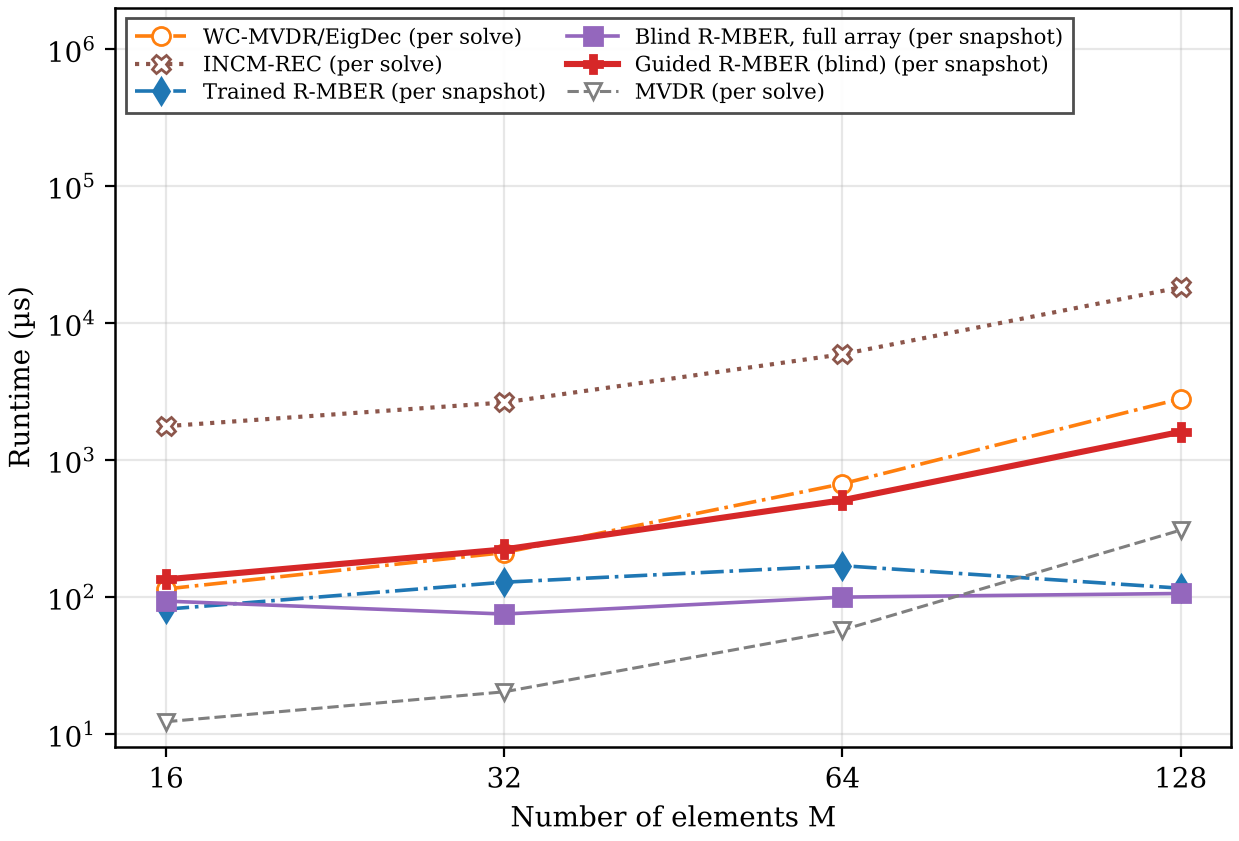

{
 "M": [
  16,
  32,
  64,
  128
 ],
 "source": "recorded run",
 "MVDR": [
  12.22,
  20.2,
  57.12,
  306.19
 ],
 "DL-MVDR": [
  10.49,
  18.61,
  55.77,
  306.7
 ],
 "WC-MVDR/EigDec": [
  113.86,
  209.85,
  667.54,
  2788.1
 ],
 "MBER": [
  26.14,
  27.12,
  28.4,
  32.0
 ],
 "trained R-MBER": [
  81.03,
  127.56,
  168.38,
  115.31
 ],
 "blind R-MBER": [
  92.77,
  74.7,
  99.26,
  105.5
 ],
 "INCM-REC": [
  1757.99,
  2619.82,
  5895.41,
  18157.89
 ],
 "TA-MMSE": [
  23.32,
  52.91,
  165.81,
  670.53
 ],
 "guide alone": [
  95.85,
  177.29,
  453.49,
  1552.94
 ],
 "guided R-MBER": [
  133.77,
  221.28,
  506.23,
  1598.69
 ]
}


In [3]:
fig_4_1()
show('Figure 4.1')

## Figure 4.2: output SINR versus steering-vector mismatch, point source, M = 8, 16, 32 and 64

All methods on the same 20 realizations. The dotted line marks half the half-power beamwidth.

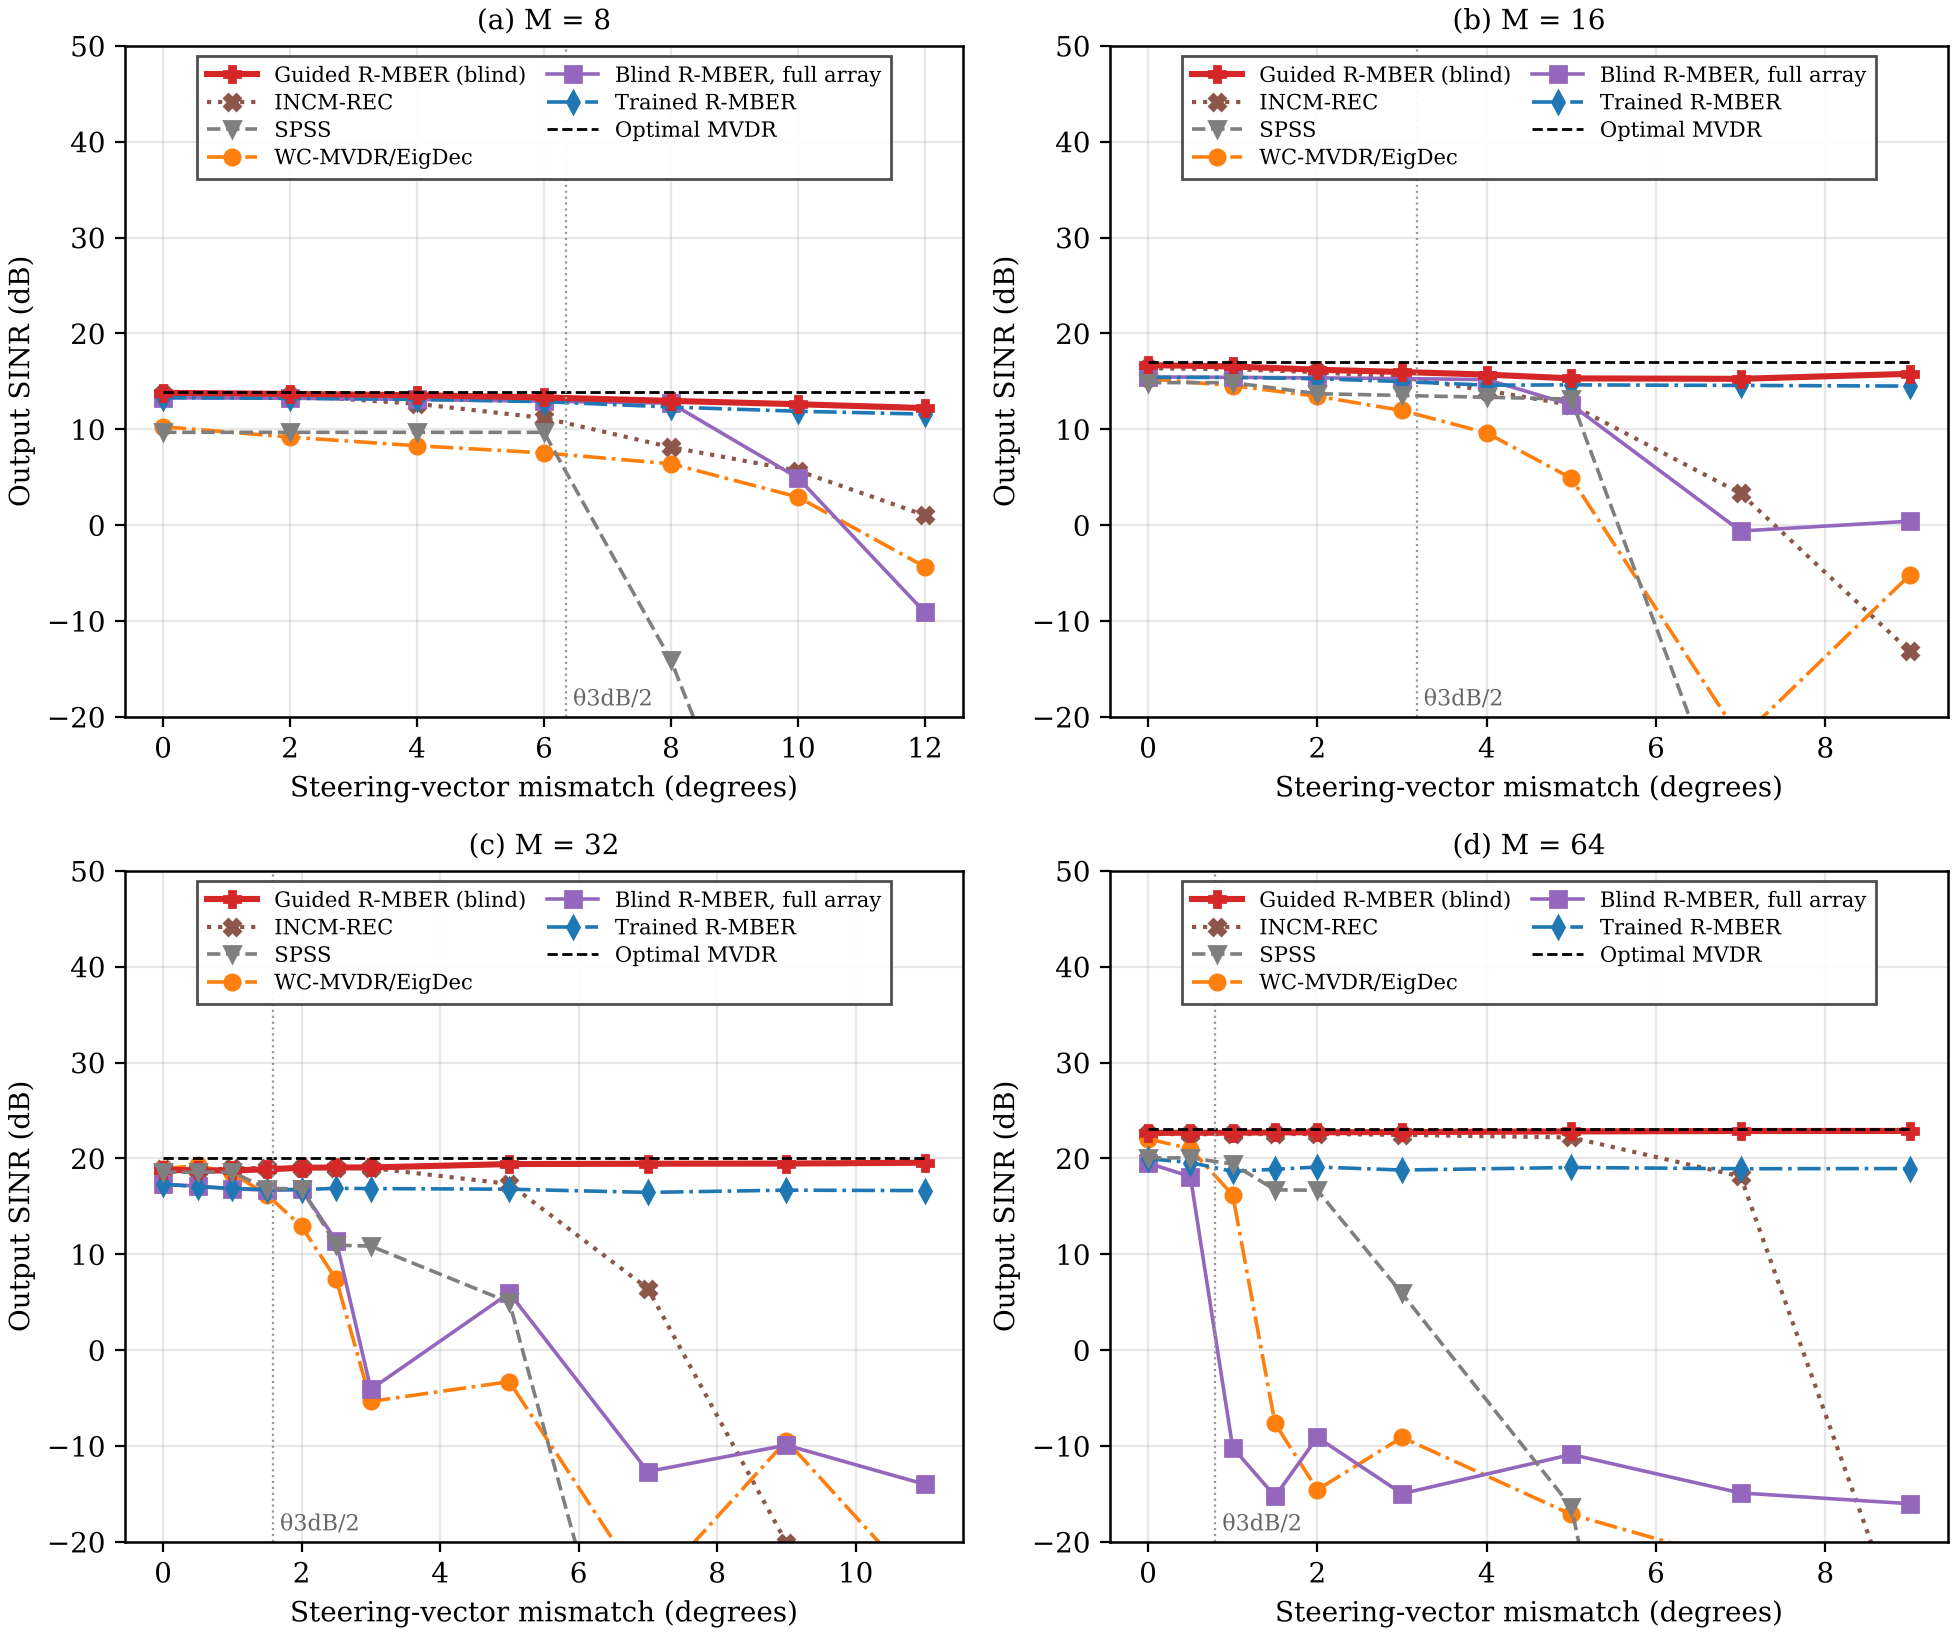

{
 "M = 8": {
  "mismatch": [
   0.0,
   2.0,
   4.0,
   6.0,
   8.0,
   10.0,
   12.0
  ],
  "Guided R-MBER (blind)": [
   13.8,
   13.69,
   13.55,
   13.32,
   12.96,
   12.61,
   12.21
  ],
  "INCM-REC": [
   13.73,
   13.52,
   12.66,
   11.18,
   8.13,
   5.68,
   1.03
  ],
  "WC-MVDR/EigDec": [
   10.27,
   9.18,
   8.28,
   7.53,
   6.4,
   2.93,
   -4.35
  ],
  "Blind R-MBER, full array": [
   13.28,
   13.24,
   13.11,
   12.92,
   12.72,
   4.93,
   -9.1
  ],
  "Trained R-MBER": [
   13.29,
   13.24,
   13.12,
   12.88,
   12.32,
   11.88,
   11.58
  ],
  "Optimal MVDR": [
   13.92,
   13.92,
   13.92,
   13.92,
   13.92,
   13.92,
   13.92
  ],
  "SPSS": [
   9.68,
   9.68,
   9.68,
   9.68,
   -14.1,
   -47.61,
   -47.41
  ],
  "failed, guided R-MBER": [
   0,
   0,
   0,
   0,
   0,
   0,
   0
  ],
  "failed, INCM-REC": [
   0,
   0,
   0,
   0,
   20,
   20,
   20
  ],
  "failed, WC-MVDR/EigDec": [
   20,
   20,
   20,
   20,
   20,
   20,
   20
  ]
 },
 "M = 16": {
  "m

In [4]:
fig_4_2()
show('Figure 4.2')

## Figure 4.3: the eight mismatch and propagation cases, M = 32

Point source, small and large angular spread at 2°, 5° and 7°; 20 block-fading realizations; dashed lines mark the optimum.

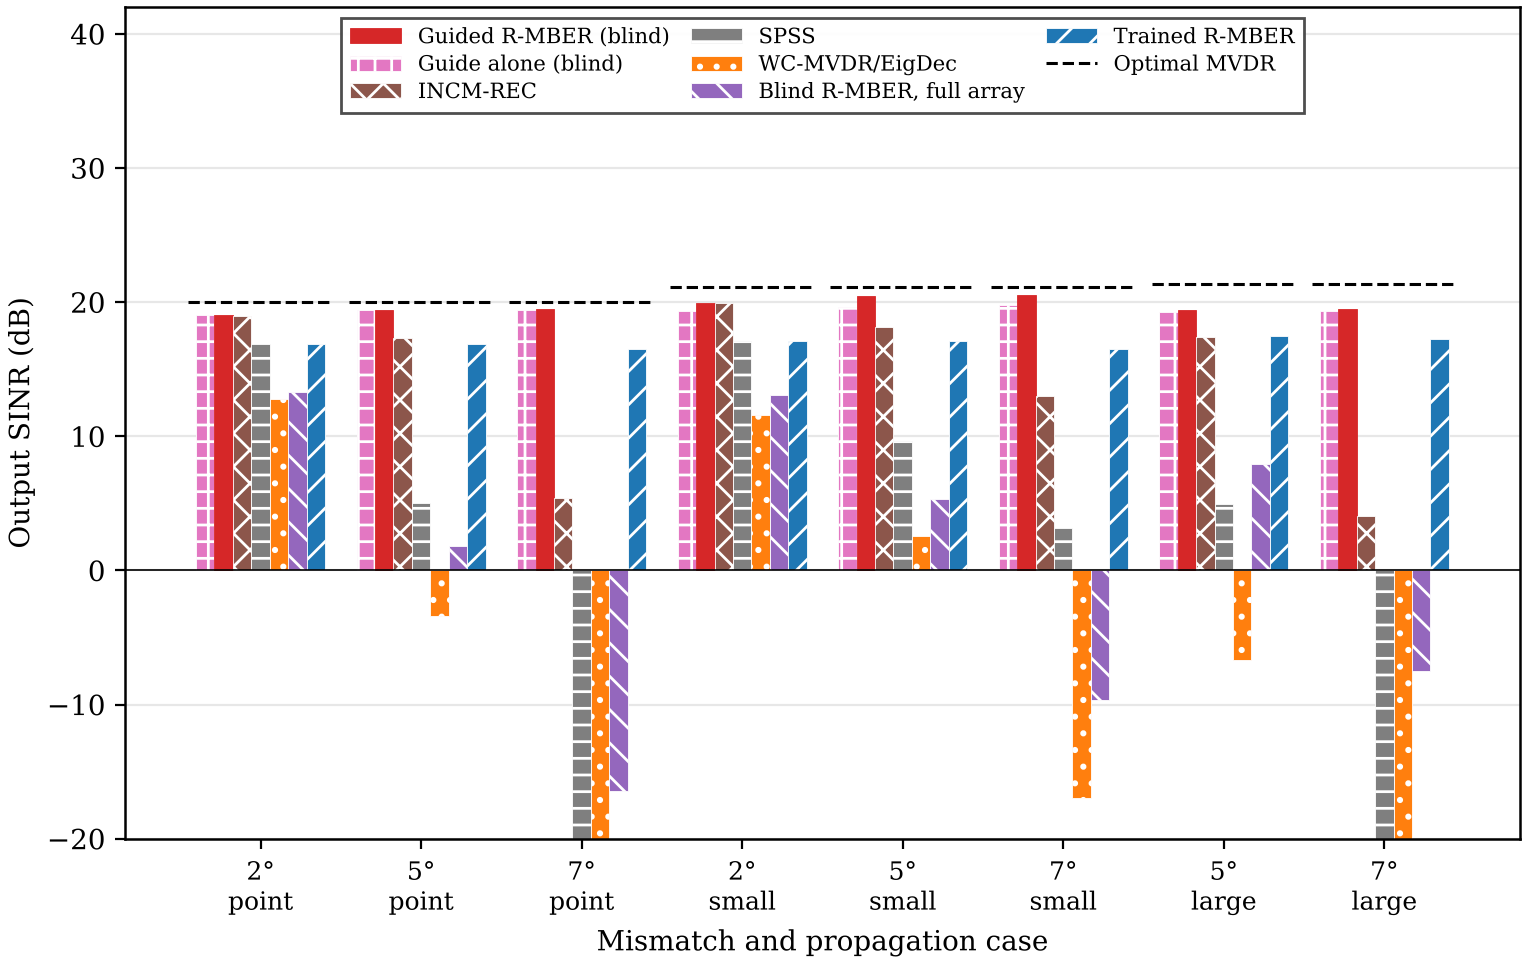

{
 "cases": [
  "2 pt",
  "5 pt",
  "7 pt",
  "2 sm",
  "5 sm",
  "7 sm",
  "5 lg",
  "7 lg"
 ],
 "Guide alone (blind)": [
  19.03,
  19.41,
  19.45,
  19.34,
  19.65,
  19.77,
  19.3,
  19.36
 ],
 "Guided R-MBER (blind)": [
  19.03,
  19.42,
  19.45,
  19.96,
  20.42,
  20.53,
  19.42,
  19.47
 ],
 "INCM-REC": [
  19.0,
  17.35,
  5.39,
  19.95,
  18.16,
  13.03,
  17.38,
  4.08
 ],
 "SPSS": [
  16.84,
  5.02,
  -47.55,
  17.14,
  9.61,
  3.12,
  4.92,
  -34.96
 ],
 "WC-MVDR/EigDec": [
  12.81,
  -3.39,
  -26.26,
  11.6,
  2.56,
  -16.98,
  -6.71,
  -23.81
 ],
 "Blind R-MBER, full array": [
  13.28,
  1.79,
  -16.42,
  13.08,
  5.34,
  -9.64,
  7.95,
  -7.48
 ],
 "Trained R-MBER": [
  16.88,
  16.86,
  16.51,
  17.1,
  17.09,
  16.51,
  17.48,
  17.27
 ],
 "Optimal MVDR": [
  20.05,
  20.05,
  20.05,
  21.16,
  21.16,
  21.16,
  21.36,
  21.36
 ],
 "failed, guide alone": [
  0,
  0,
  0,
  3,
  2,
  1,
  0,
  0
 ],
 "failed, guided R-MBER": [
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0
 ]


In [5]:
fig_4_3()
show('Figure 4.3')

## Figure 4.4: output SINR versus the number of snapshots processed, 7° mismatch

Guided form recomputed on every block length (every five snapshots), 12 realizations.

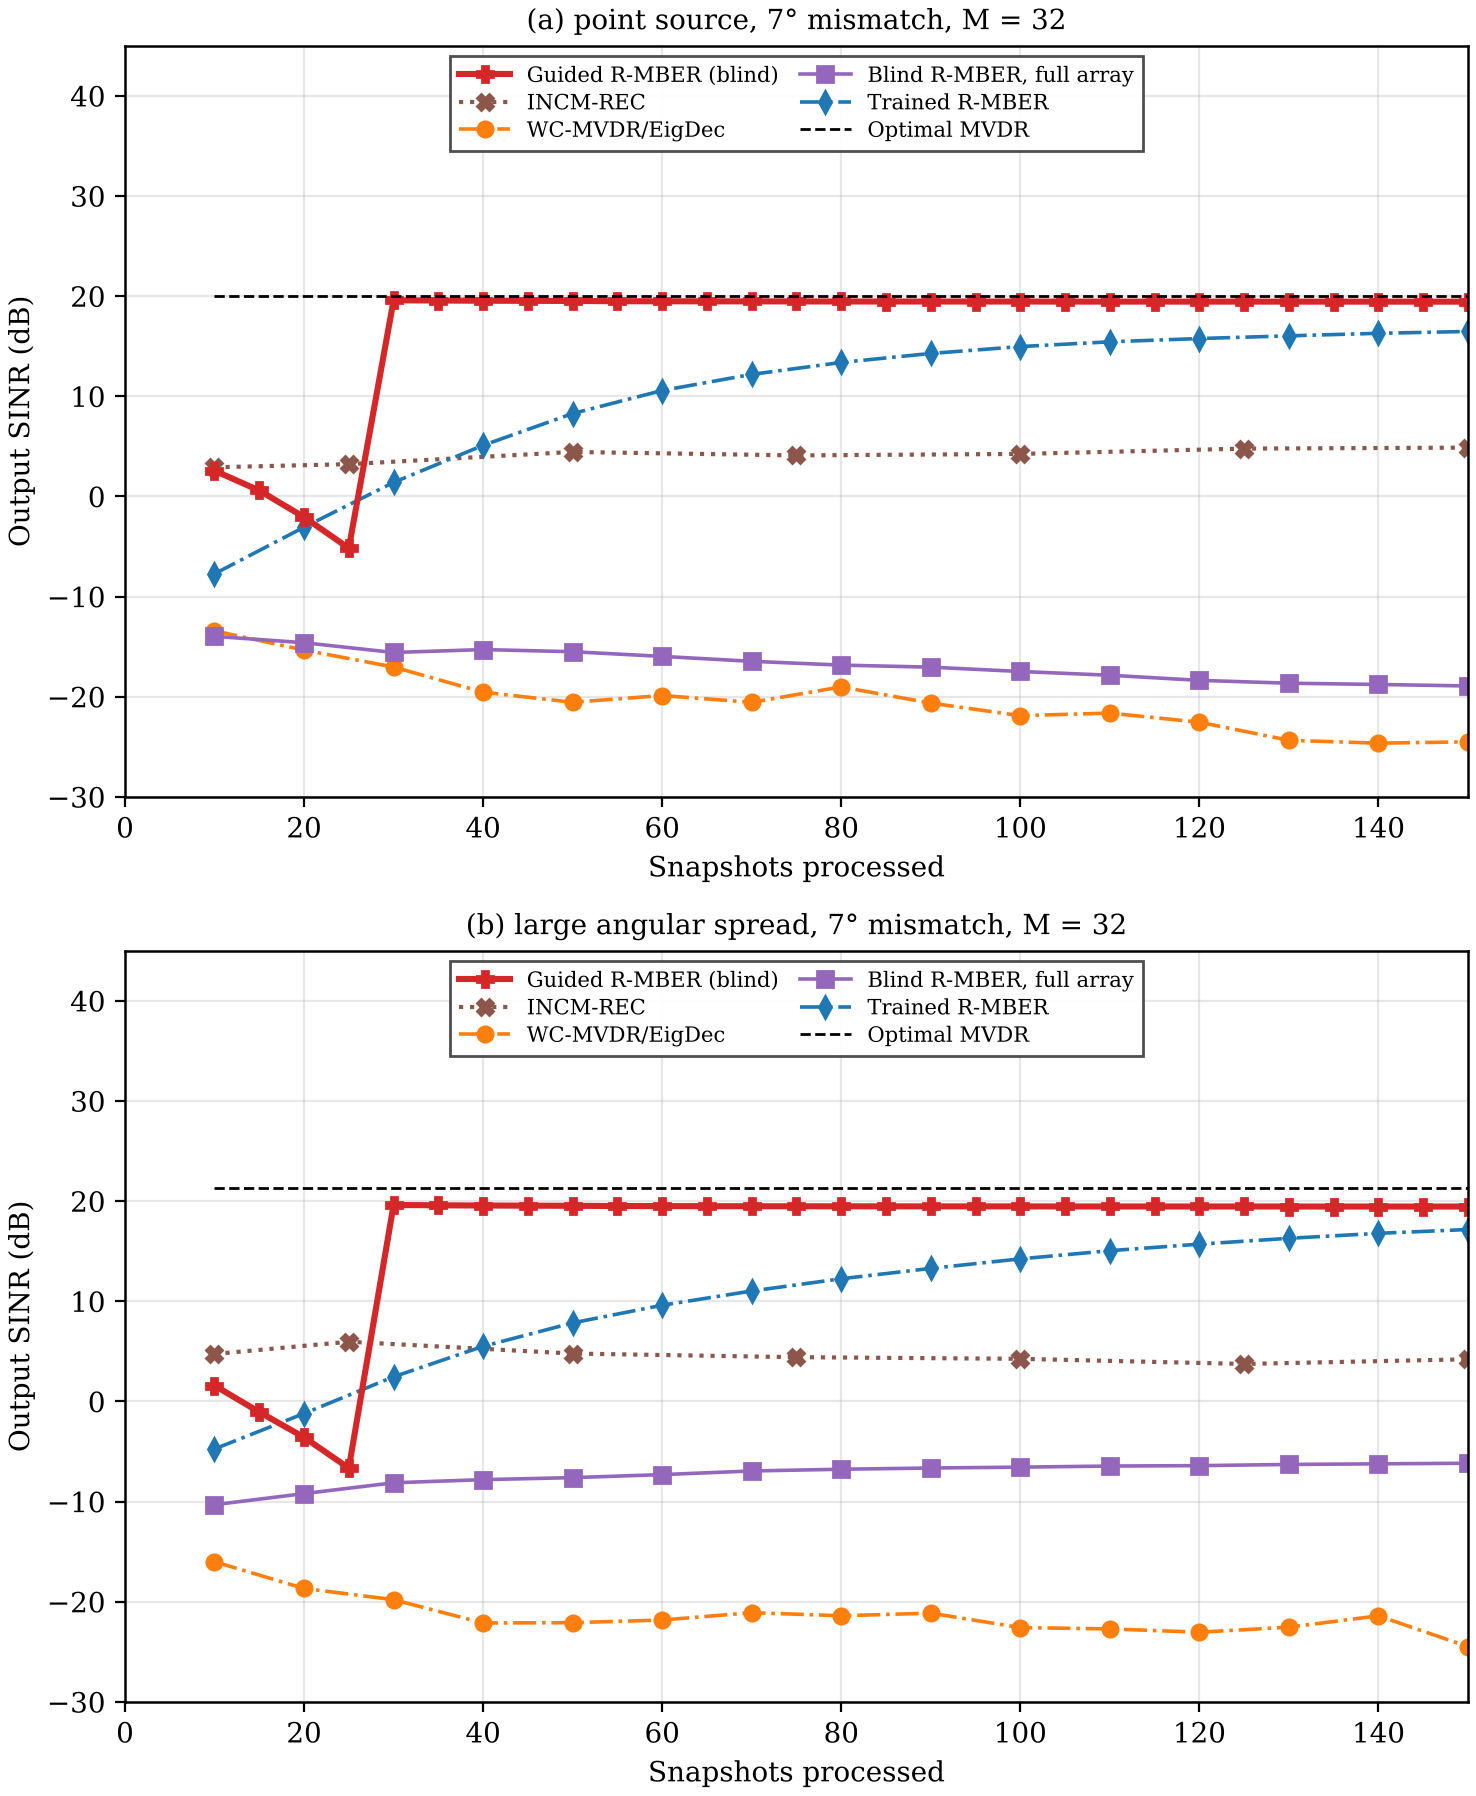

{
 "pt": {
  "guided R-MBER, block lengths": [
   10,
   15,
   20,
   25,
   30,
   35,
   40,
   45,
   50,
   55,
   60,
   65,
   70,
   75,
   80,
   85,
   90,
   95,
   100,
   105,
   110,
   115,
   120,
   125,
   130,
   135,
   140,
   145,
   150
  ],
  "guided R-MBER": [
   2.57,
   0.59,
   -2.06,
   -5.17,
   19.58,
   19.56,
   19.54,
   19.53,
   19.52,
   19.49,
   19.49,
   19.48,
   19.48,
   19.48,
   19.47,
   19.46,
   19.46,
   19.46,
   19.46,
   19.46,
   19.45,
   19.46,
   19.45,
   19.45,
   19.45,
   19.45,
   19.45,
   19.45,
   19.45
  ],
  "guide alone": [
   2.14,
   0.04,
   -2.06,
   -4.34,
   19.6,
   19.6,
   19.6,
   19.6,
   19.6,
   19.49,
   19.49,
   19.49,
   19.49,
   19.49,
   19.46,
   19.46,
   19.46,
   19.46,
   19.46,
   19.45,
   19.45,
   19.45,
   19.45,
   19.45,
   19.44,
   19.44,
   19.44,
   19.44,
   19.44
  ],
  "trained R-MBER at 10, 50, 100, 150": [
   -7.73,
   8.28,
   14.96,
   16.47
  ],
  "WC-MVDR/EigDec max": -12.74,

In [6]:
fig_4_4()
show('Figure 4.4')

## Figure 4.5: model-based BER versus mismatch, element SNR −5 dB

15 realizations per point; BPSK with ideal carrier-phase recovery.

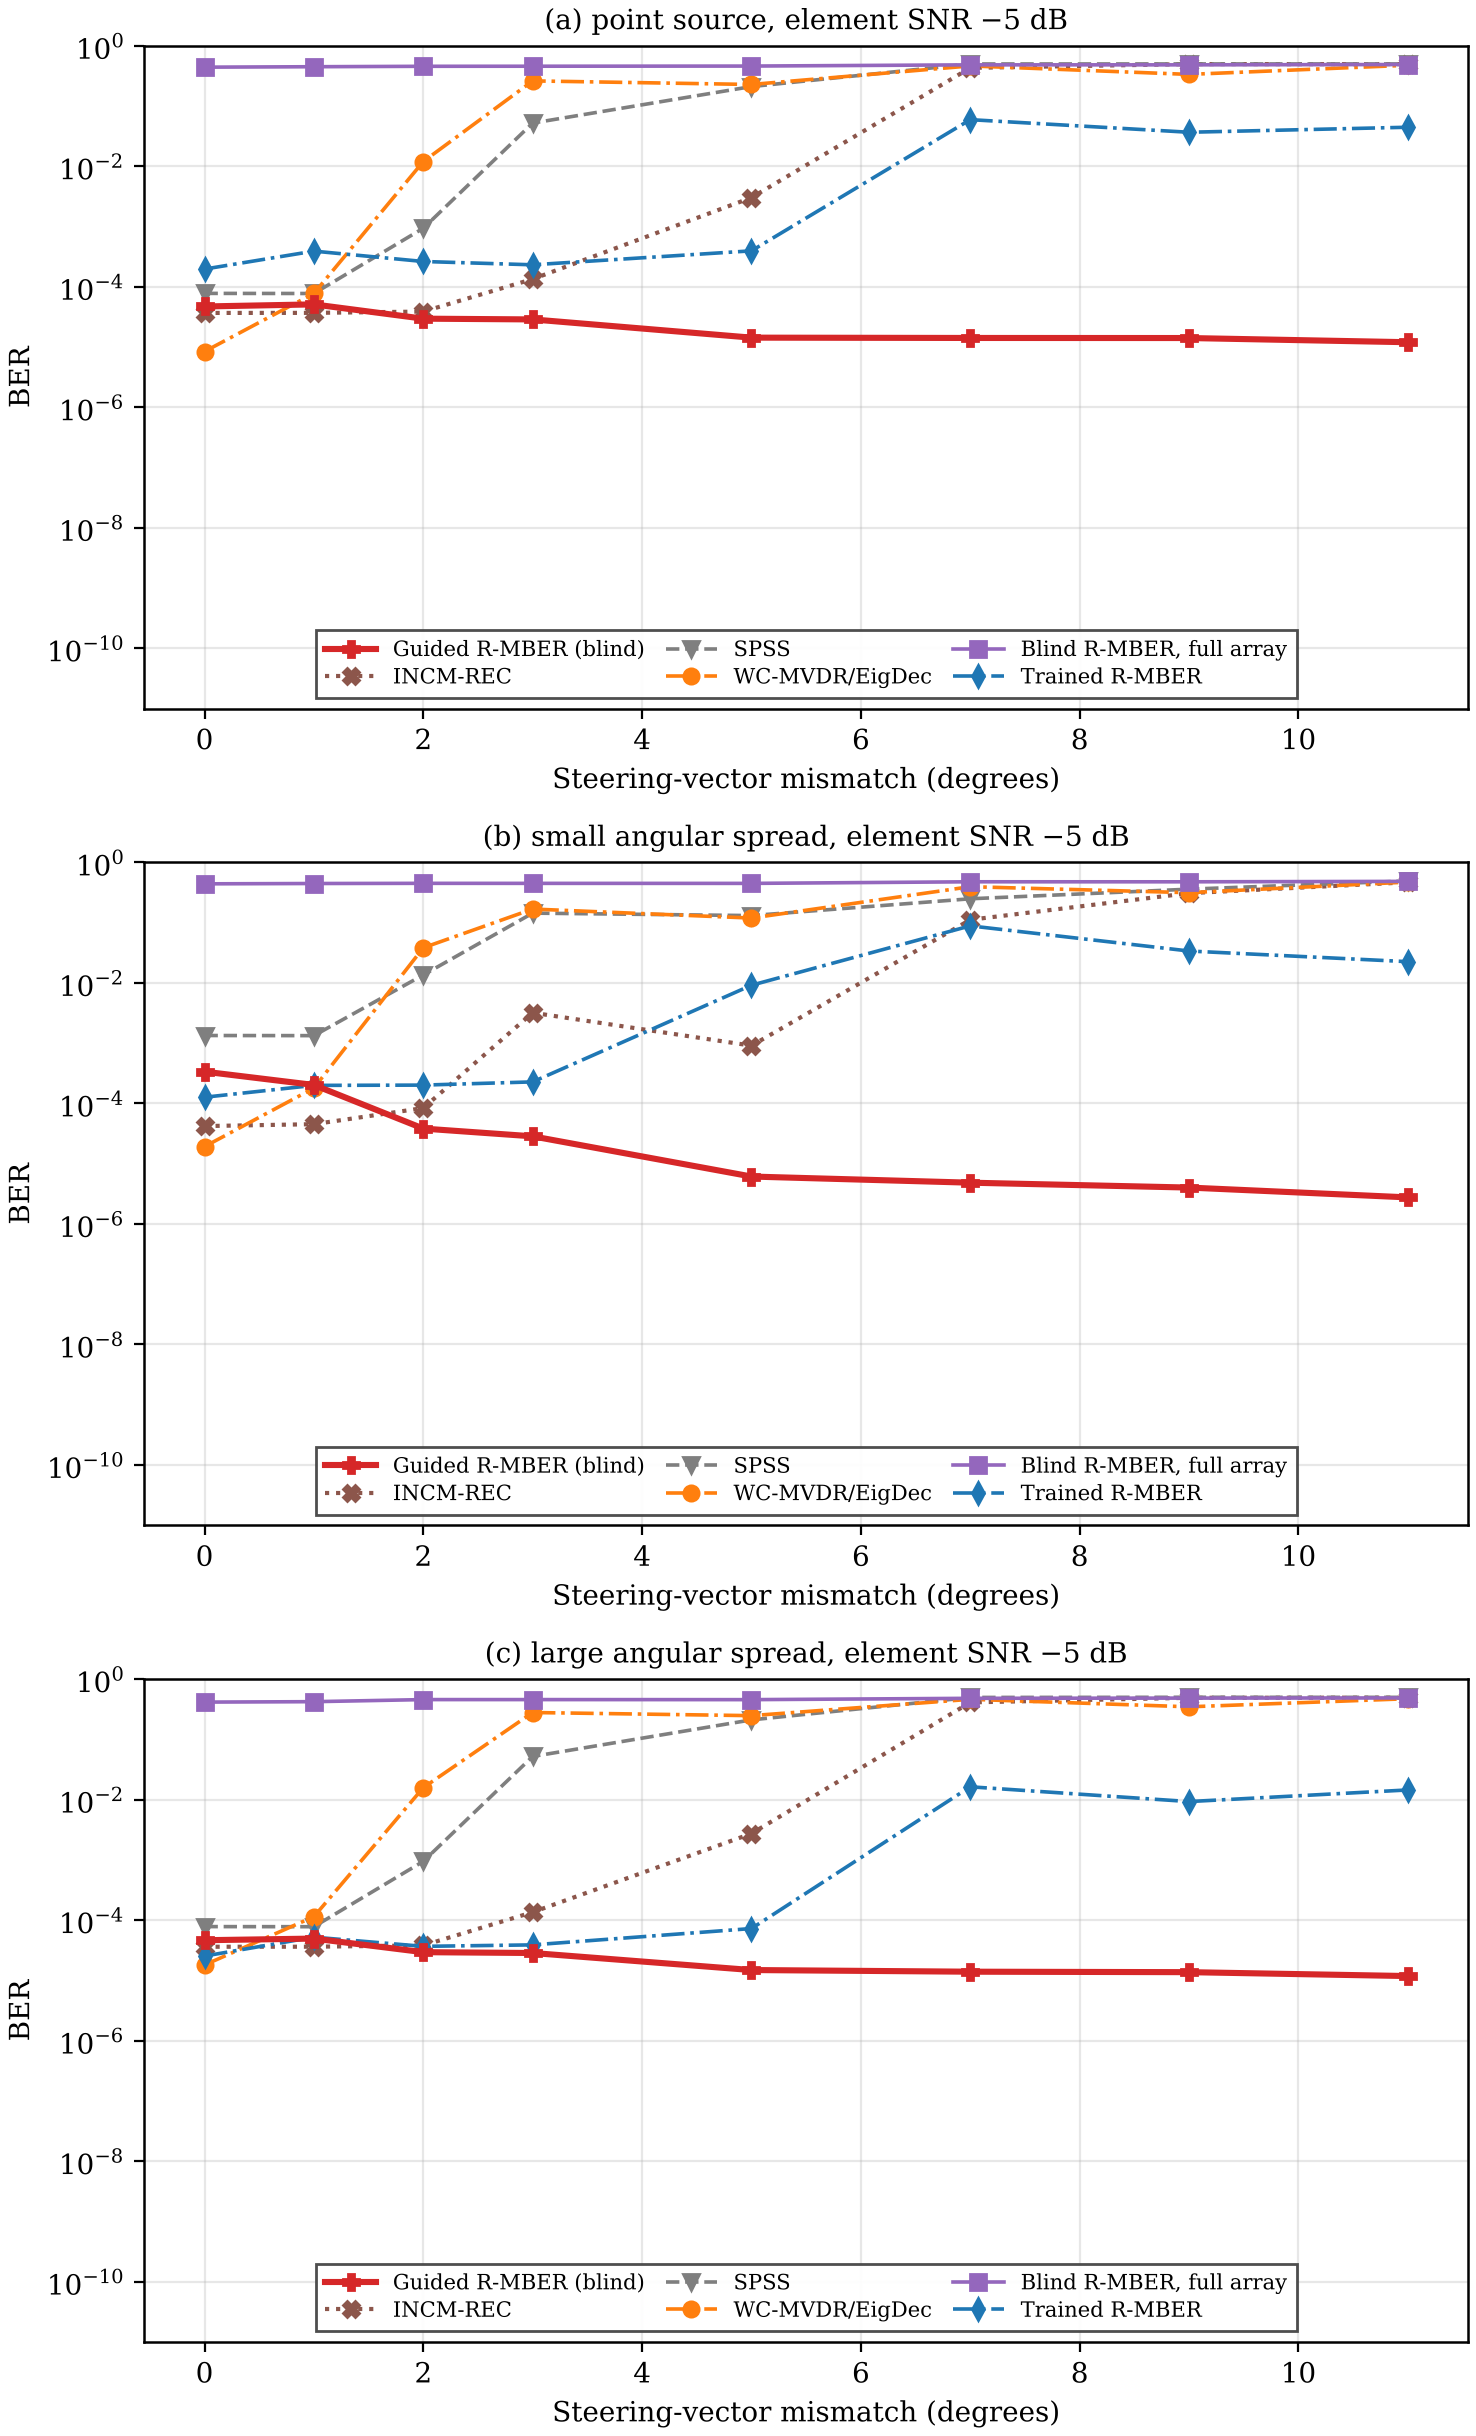

{
 "point source": {
  "x": [
   0.0,
   1.0,
   2.0,
   3.0,
   5.0,
   7.0,
   9.0,
   11.0
  ],
  "guided R-MBER": [
   4.711221678075868e-05,
   5.103966551019432e-05,
   2.9569409126670287e-05,
   2.8729989442498466e-05,
   1.4318270777611624e-05,
   1.4145083051443692e-05,
   1.4108573290086054e-05,
   1.2022434744269822e-05
  ],
  "guide alone": [
   5.036818373715091e-05,
   5.8555861426308273e-05,
   3.7807473064989605e-05,
   3.4381793993656455e-05,
   1.7260186143487174e-05,
   1.5198971257561678e-05,
   1.44063026999043e-05,
   1.2309806722437848e-05
  ],
  "INCM-REC": [
   3.682092725388248e-05,
   3.6901254370905766e-05,
   3.877149337607167e-05,
   0.0001341677308423422,
   0.0030189451104106783,
   0.42975491453811804,
   0.4968088845955373,
   0.4955902745451256
  ],
  "WC-MVDR/EigDec": [
   8.42285629497339e-06,
   7.762113193863707e-05,
   0.011980036846075069,
   0.26129514432021145,
   0.22791123525964413,
   0.4631132247015773,
   0.33485621987083697,
   0.4754492

In [7]:
fig_4_5()
show('Figure 4.5')

## Figure 4.6: model-based BER versus element SNR, 5° mismatch

Values below 1e-16 are drawn at 1e-16.

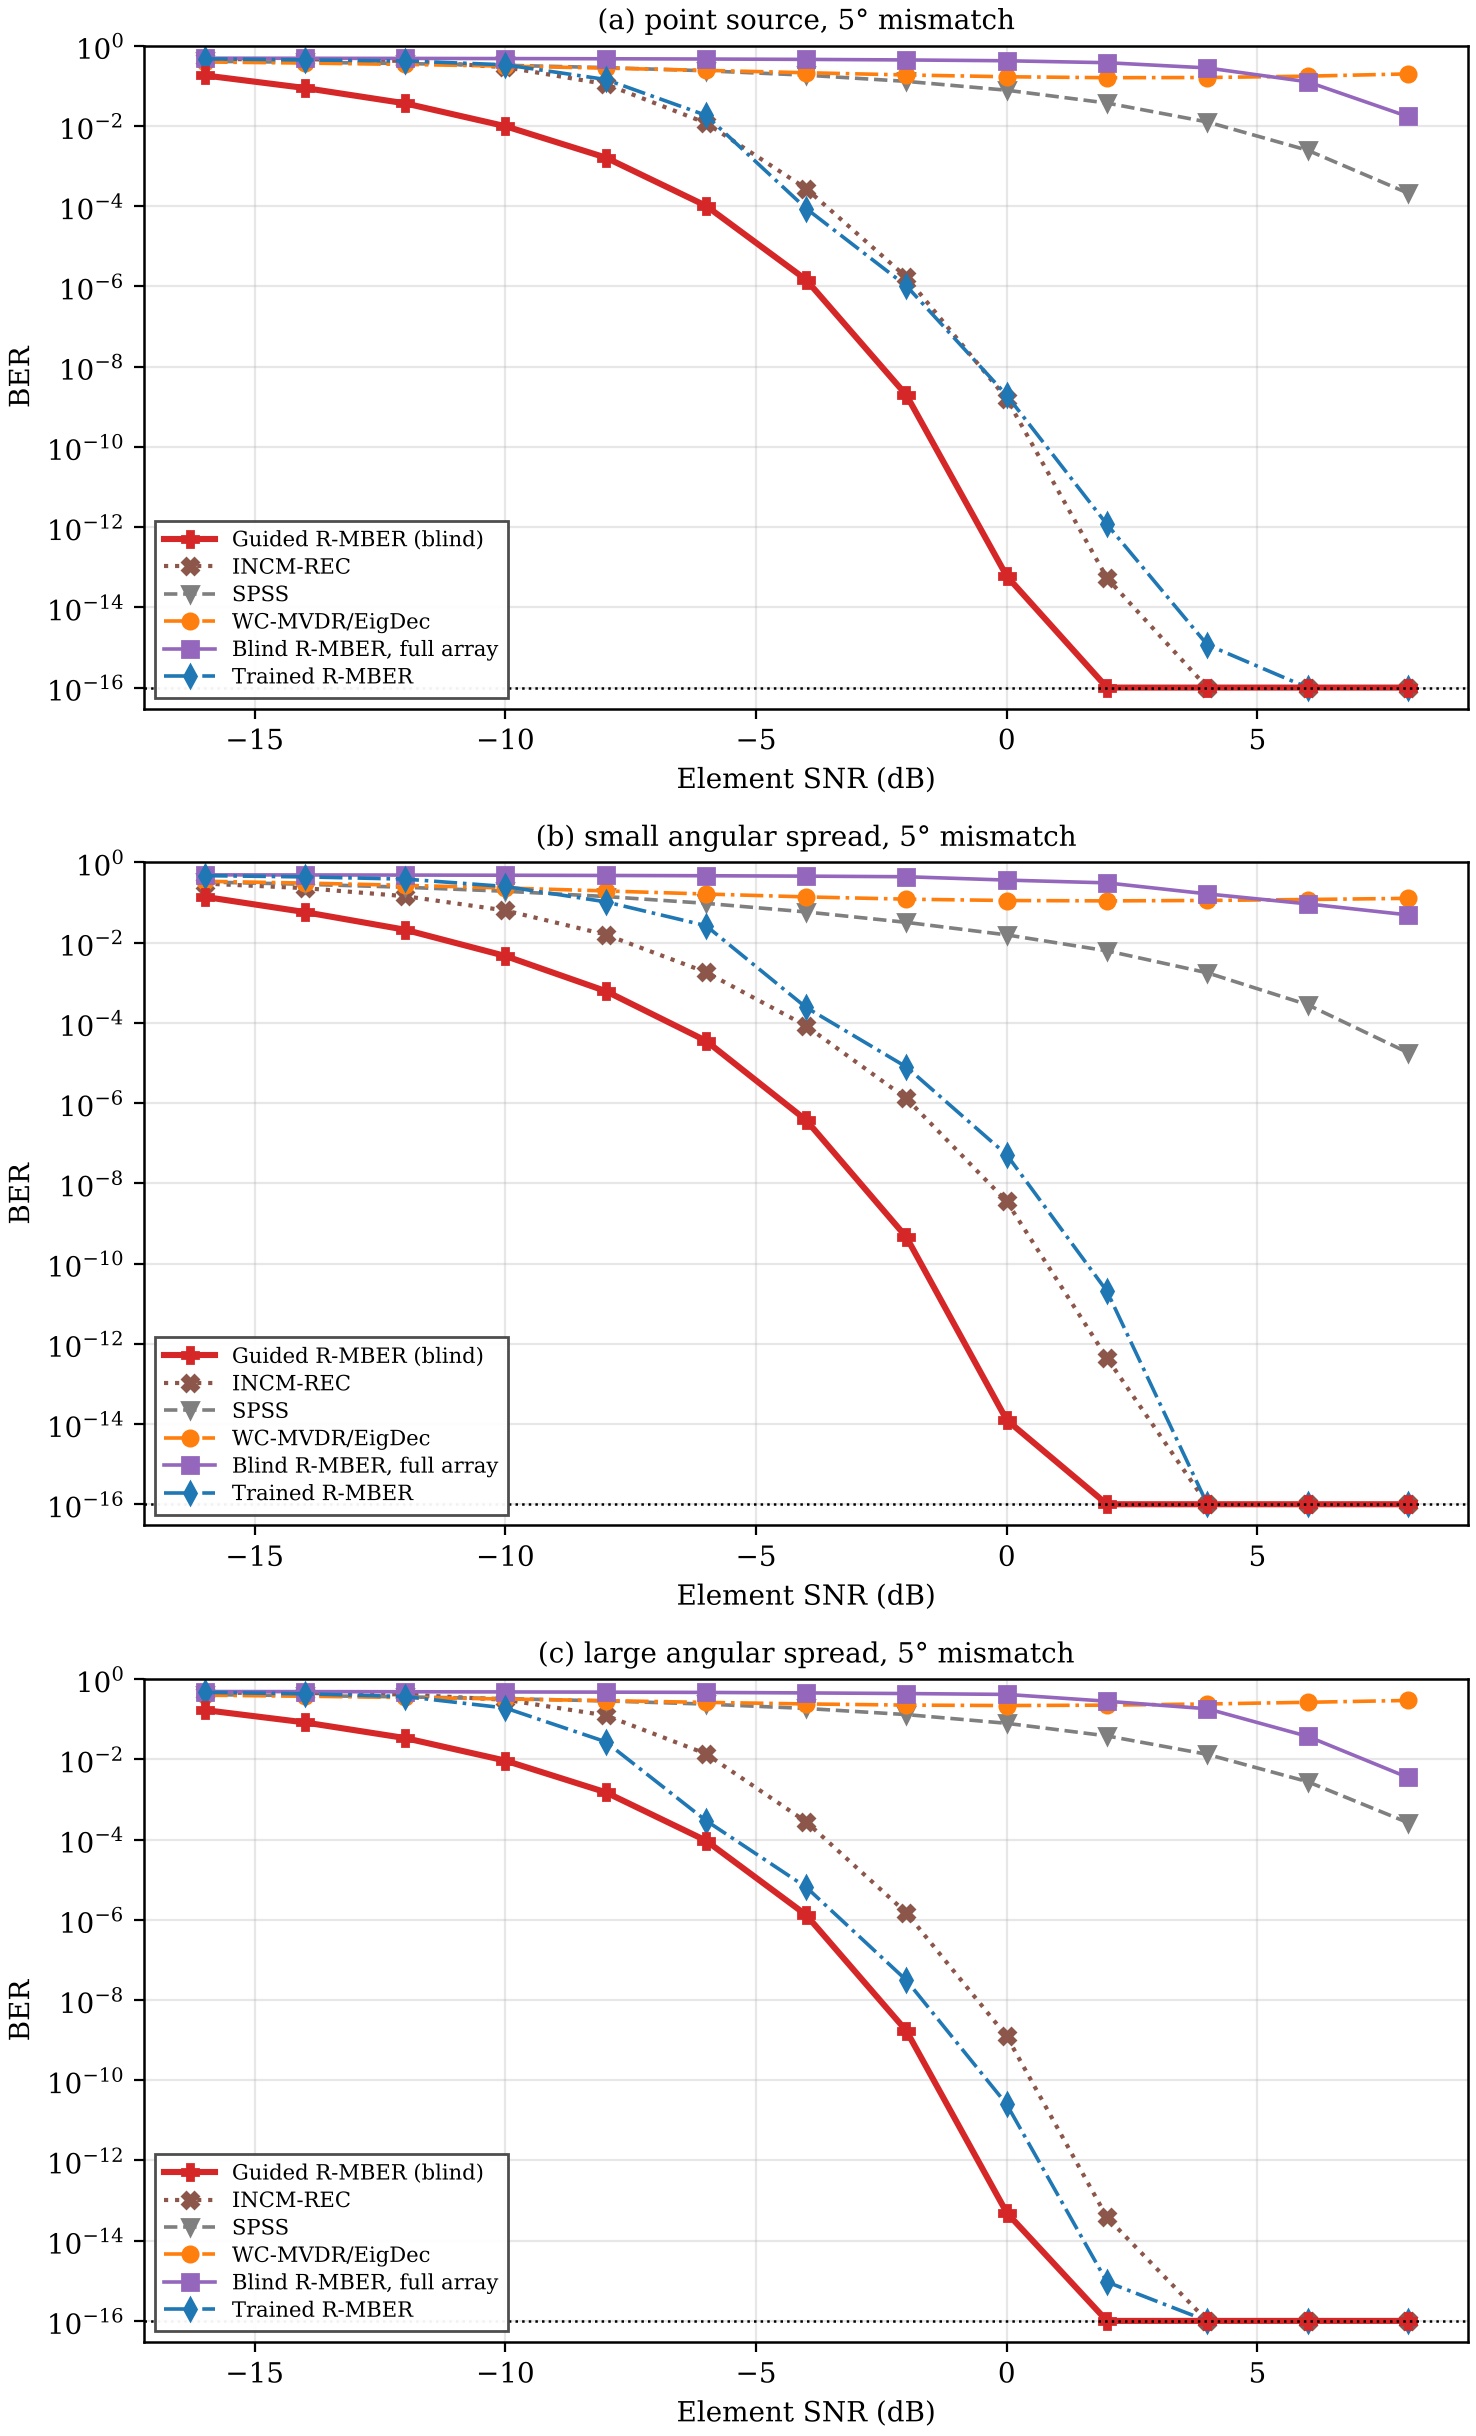

{
 "point source": {
  "x": [
   -16,
   -14,
   -12,
   -10,
   -8,
   -6,
   -4,
   -2,
   0,
   2,
   4,
   6,
   8
  ],
  "guided R-MBER": [
   0.18287151445720098,
   0.08868583138439132,
   0.03673439079946426,
   0.009895328298348207,
   0.0016376916829868638,
   0.00010289822603300281,
   1.4668175874215046e-06,
   1.949559544315836e-09,
   6.014293515165069e-14,
   4.700478818230991e-21,
   2.719007774262975e-32,
   4.1094804383331725e-50,
   1.922859094724338e-78
  ],
  "guide alone": [
   0.1307263495585296,
   0.07495173733109067,
   0.03393739798127955,
   0.010359420850573458,
   0.0017407771834462118,
   0.00011342316873665052,
   1.65519859796443e-06,
   2.2580411815680454e-09,
   7.163021660284376e-14,
   5.7589640834897204e-21,
   3.423816391496075e-32,
   5.318916812305159e-50,
   2.5745332007983725e-78
  ],
  "INCM-REC": [
   0.46338523935752485,
   0.4632555445832748,
   0.4190197979921371,
   0.29237781215205366,
   0.11089456108512868,
   0.01192187964936257,
   

In [8]:
fig_4_6()
show('Figure 4.6')

## Figure 4.7: output SINR versus the INR of each interferer

Point source, K = 150 and K = 1000, 5° and 7° of mismatch.

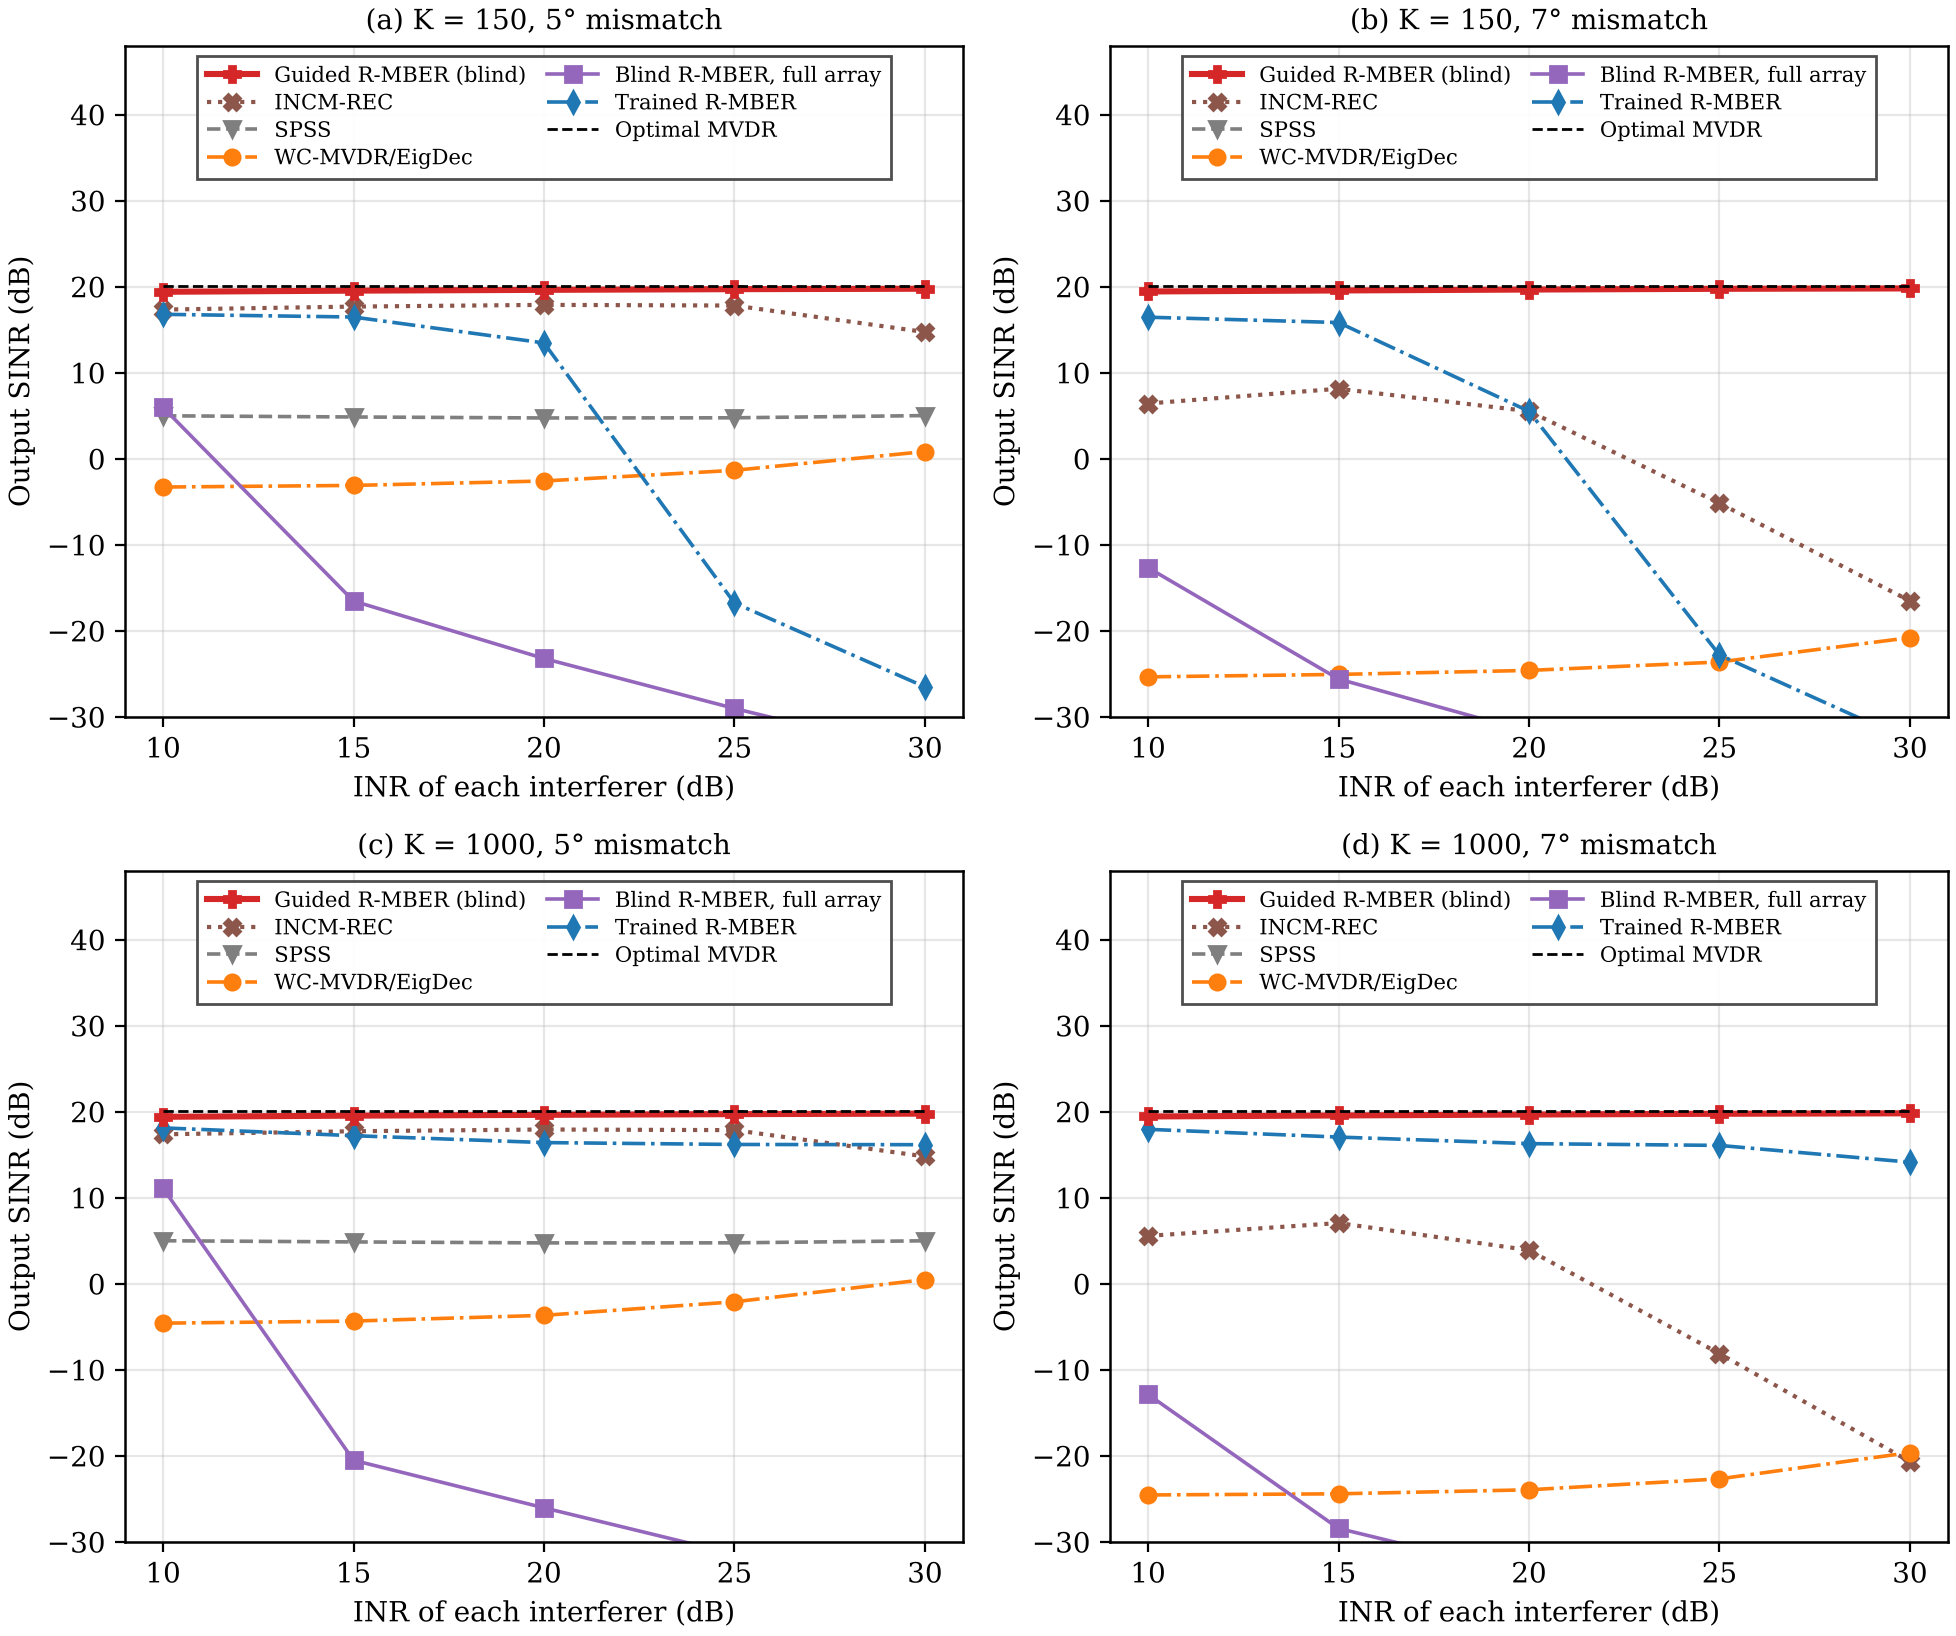

{
 "K = 150, 5 deg": {
  "INR": [
   10,
   15,
   20,
   25,
   30
  ],
  "guided R-MBER": [
   19.41,
   19.54,
   19.63,
   19.71,
   19.76
  ],
  "INCM-REC": [
   17.34,
   17.69,
   17.89,
   17.81,
   14.73
  ],
  "Trained R-MBER": [
   16.79,
   16.47,
   13.46,
   -16.76,
   -26.51
  ],
  "failed, guided R-MBER": [
   0,
   0,
   0,
   0,
   0
  ]
 },
 "K = 150, 7 deg": {
  "INR": [
   10,
   15,
   20,
   25,
   30
  ],
  "guided R-MBER": [
   19.44,
   19.56,
   19.67,
   19.75,
   19.8
  ],
  "INCM-REC": [
   6.42,
   8.14,
   5.53,
   -5.17,
   -16.51
  ],
  "Trained R-MBER": [
   16.45,
   15.83,
   5.52,
   -22.8,
   -32.78
  ],
  "failed, guided R-MBER": [
   0,
   0,
   0,
   0,
   0
  ]
 },
 "K = 1000, 5 deg": {
  "INR": [
   10,
   15,
   20,
   25,
   30
  ],
  "guided R-MBER": [
   19.41,
   19.54,
   19.64,
   19.72,
   19.77
  ],
  "INCM-REC": [
   17.37,
   17.73,
   17.93,
   17.86,
   14.8
  ],
  "Trained R-MBER": [
   18.12,
   17.21,
   16.41,
   16.19,
   16

In [9]:
fig_4_7()
show('Figure 4.7')

## Figure 4.8: element SNR and number of interferers

Element SNR at 2° and 5°; 2 to 16 interferers of 10 dB INR in random directions between 15° and 70° on either side of the source at 3° and 7°.

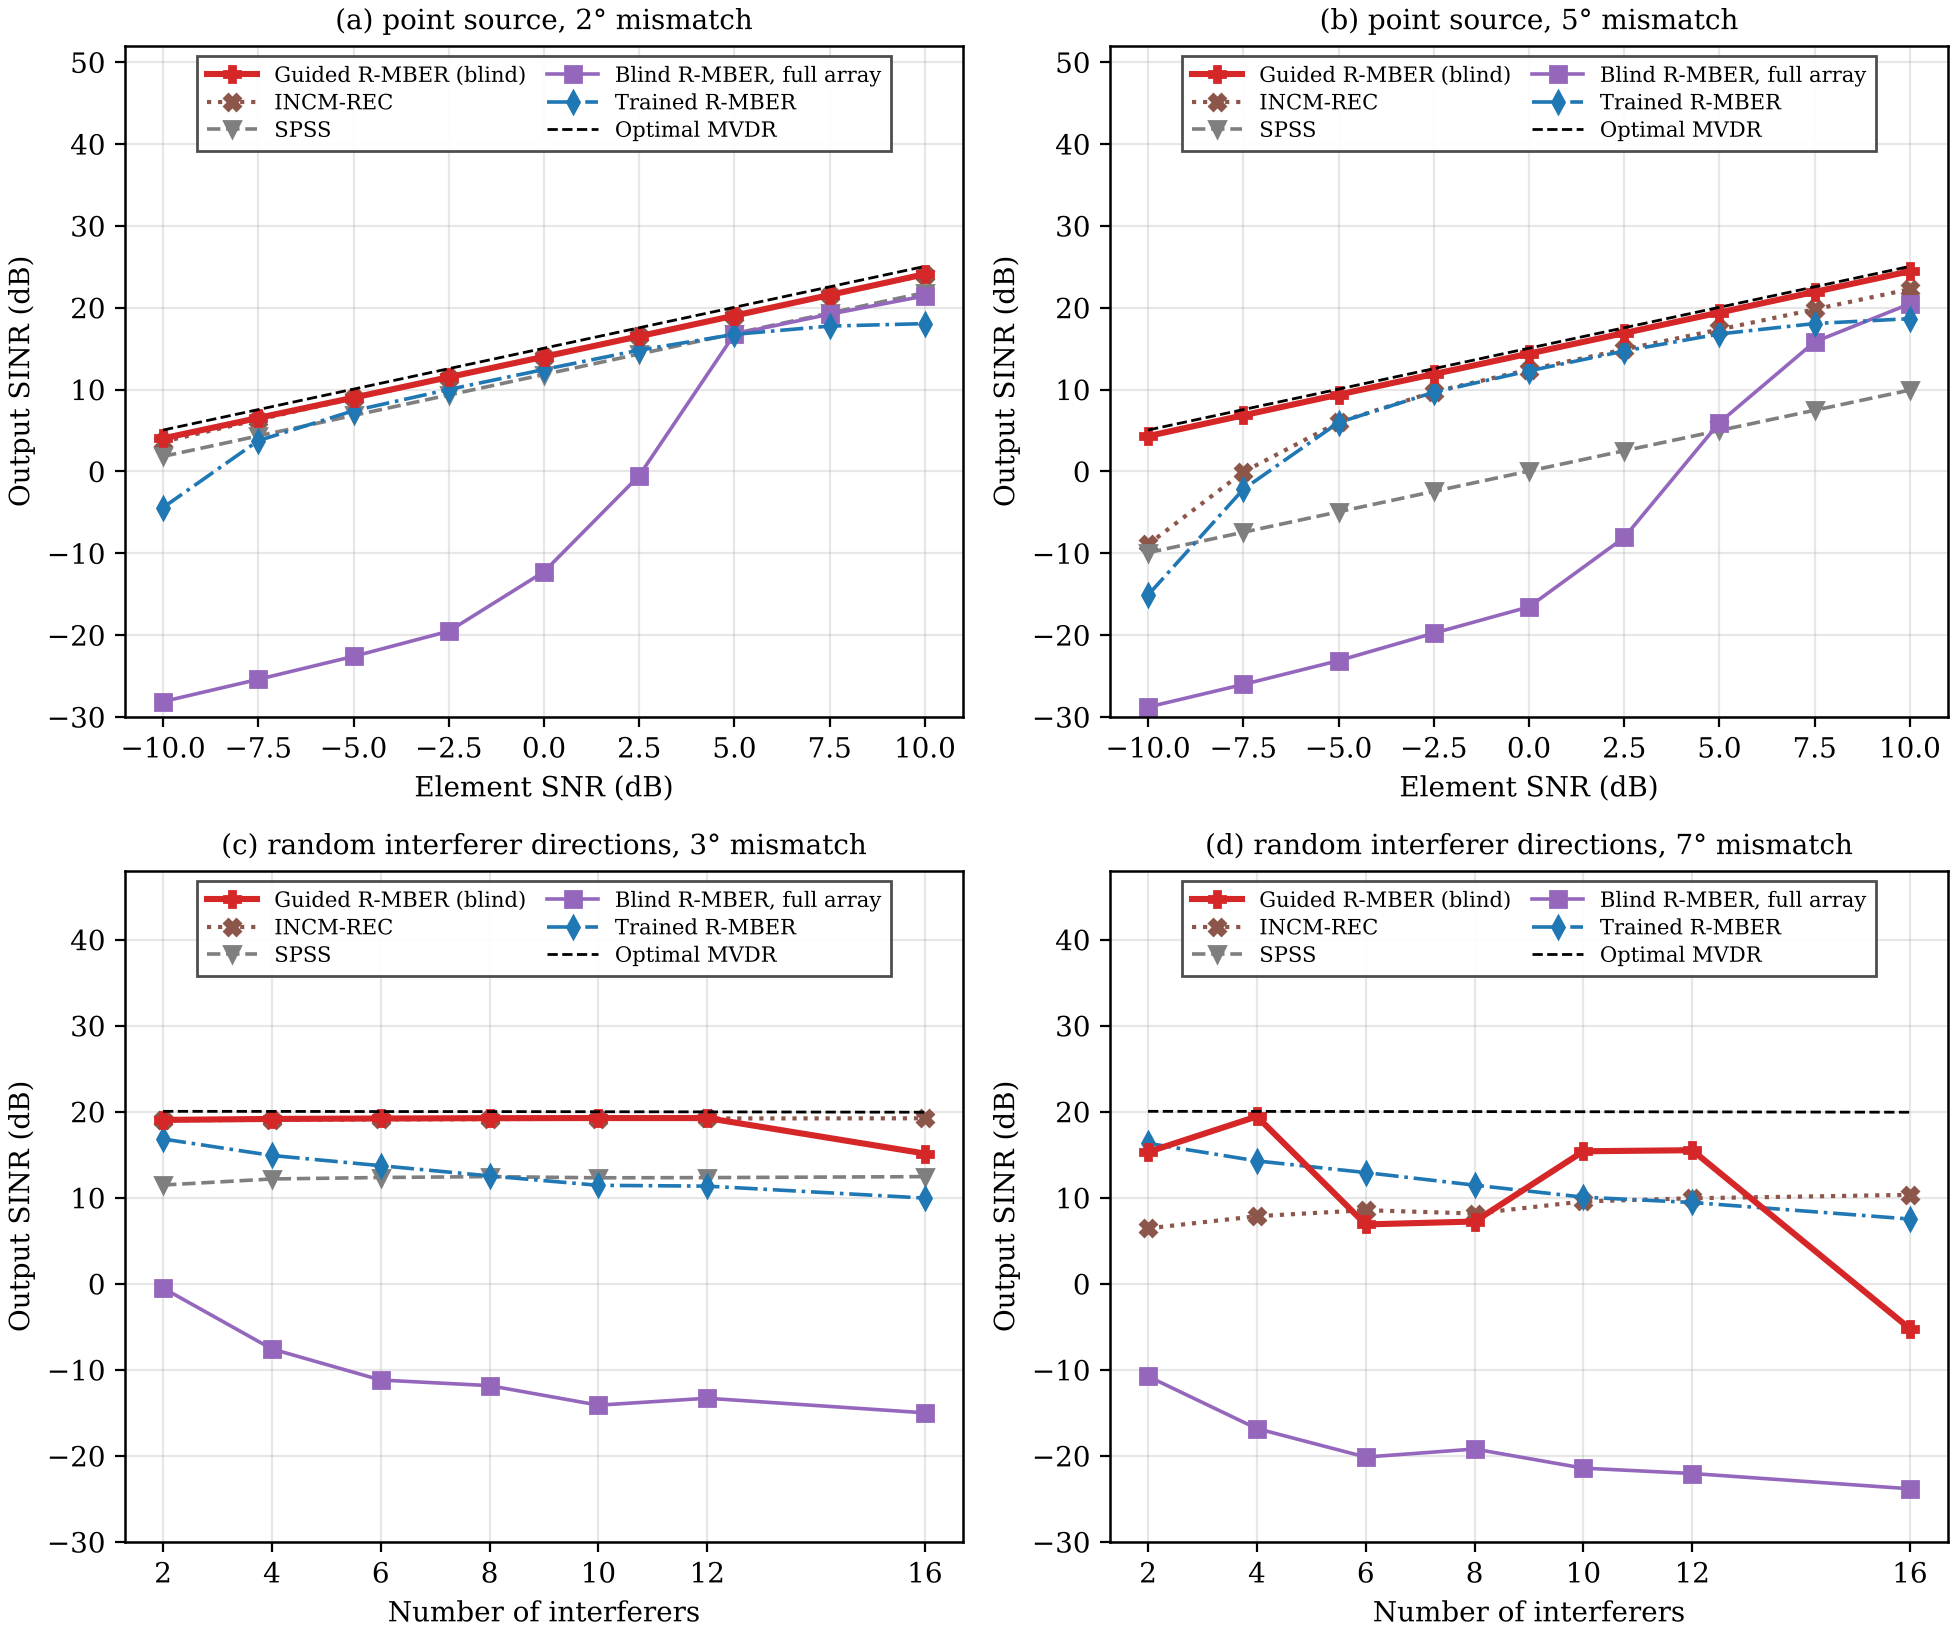

{
 "SNR, 2 deg": {
  "SNR": [
   -10,
   -7.5,
   -5,
   -2.5,
   0,
   2.5,
   5,
   7.5,
   10
  ],
  "guided R-MBER": [
   4.03,
   6.53,
   9.01,
   11.51,
   14.0,
   16.51,
   19.02,
   21.55,
   24.1
  ],
  "optimum": [
   5.05,
   7.55,
   10.05,
   12.55,
   15.05,
   17.55,
   20.05,
   22.55,
   25.05
  ],
  "INCM-REC": [
   3.62,
   6.32,
   8.92,
   11.47,
   13.98,
   16.49,
   19.0,
   21.5,
   24.0
  ],
  "failed, guided R-MBER": [
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0
  ]
 },
 "SNR, 5 deg": {
  "SNR": [
   -10,
   -7.5,
   -5,
   -2.5,
   0,
   2.5,
   5,
   7.5,
   10
  ],
  "guided R-MBER": [
   4.31,
   6.85,
   9.37,
   11.88,
   14.39,
   16.9,
   19.41,
   21.93,
   24.45
  ],
  "optimum": [
   5.05,
   7.55,
   10.05,
   12.55,
   15.05,
   17.55,
   20.05,
   22.55,
   25.05
  ],
  "INCM-REC": [
   -8.93,
   -0.08,
   5.99,
   9.71,
   12.43,
   14.9,
   17.34,
   19.79,
   22.26
  ],
  "failed, guided R-MBER": [
   0,
   0,
   0,
   0,
   0,
   

In [10]:
fig_4_8()
show('Figure 4.8')

## Figure 4.9: a third interferer near the source, 3° mismatch

Third interferer of 10 dB INR between 3° and 14° from the source.

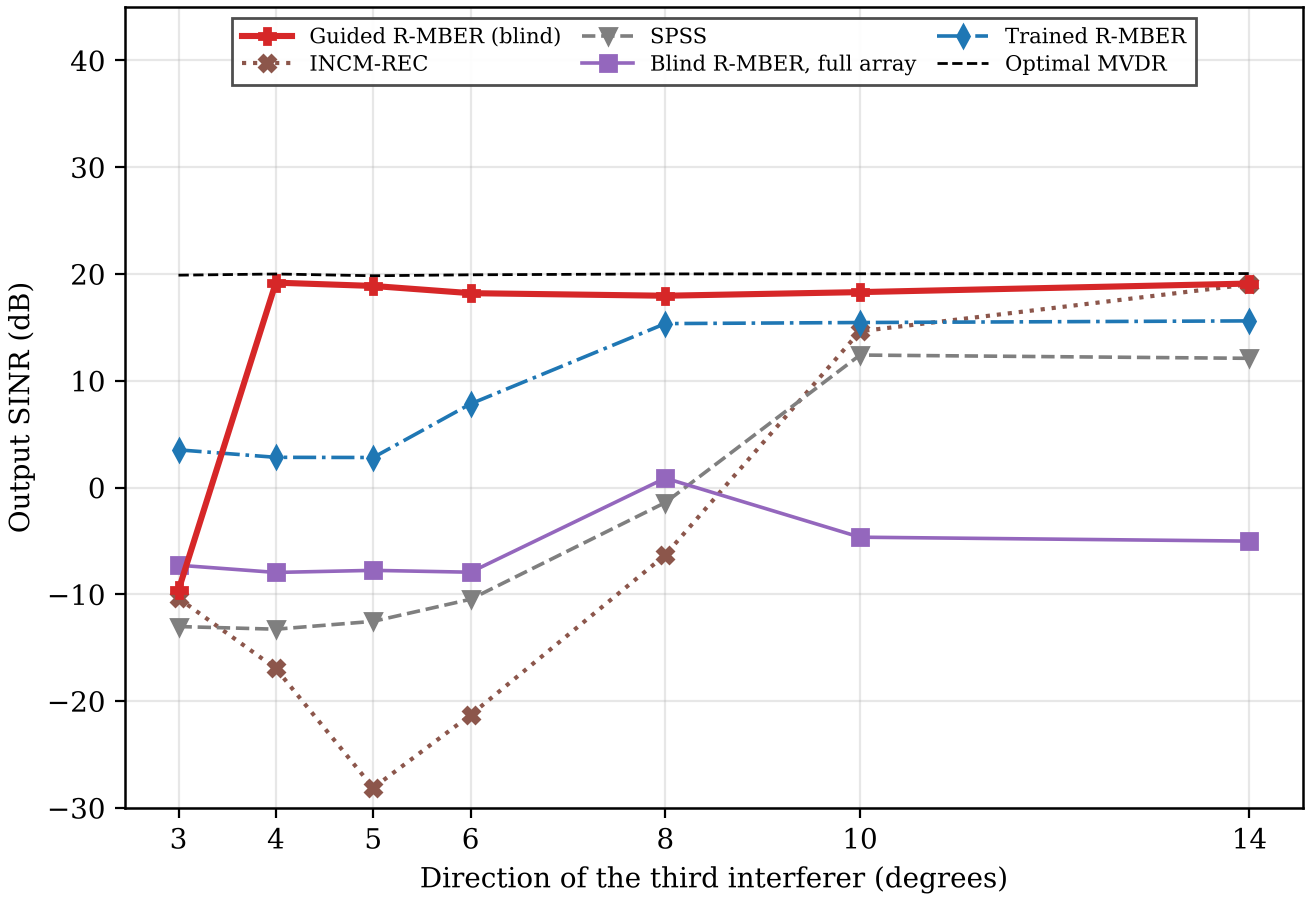

{
 "direction": [
  3.0,
  4.0,
  5.0,
  6.0,
  8.0,
  10.0,
  14.0
 ],
 "guided R-MBER": [
  -9.6,
  19.19,
  18.88,
  18.21,
  17.97,
  18.3,
  19.11
 ],
 "INCM-REC": [
  -10.37,
  -16.95,
  -28.12,
  -21.3,
  -6.32,
  14.64,
  19.03
 ],
 "SPSS": [
  -13.02,
  -13.26,
  -12.53,
  -10.46,
  -1.4,
  12.41,
  12.1
 ],
 "Trained R-MBER": [
  3.53,
  2.83,
  2.82,
  7.84,
  15.36,
  15.46,
  15.61
 ],
 "failed, guided R-MBER": [
  20,
  0,
  0,
  0,
  0,
  0,
  0
 ],
 "guided R-MBER, no mismatch": [
  -6.76,
  19.6,
  19.71,
  19.77,
  19.33,
  18.8,
  18.82
 ]
}


In [11]:
fig_4_9()
show('Figure 4.9')

## Figure 4.10: imperfect training reference

A preamble of 30 pilots, then 120 data symbols; SINR averaged over the data part; 20 realizations.

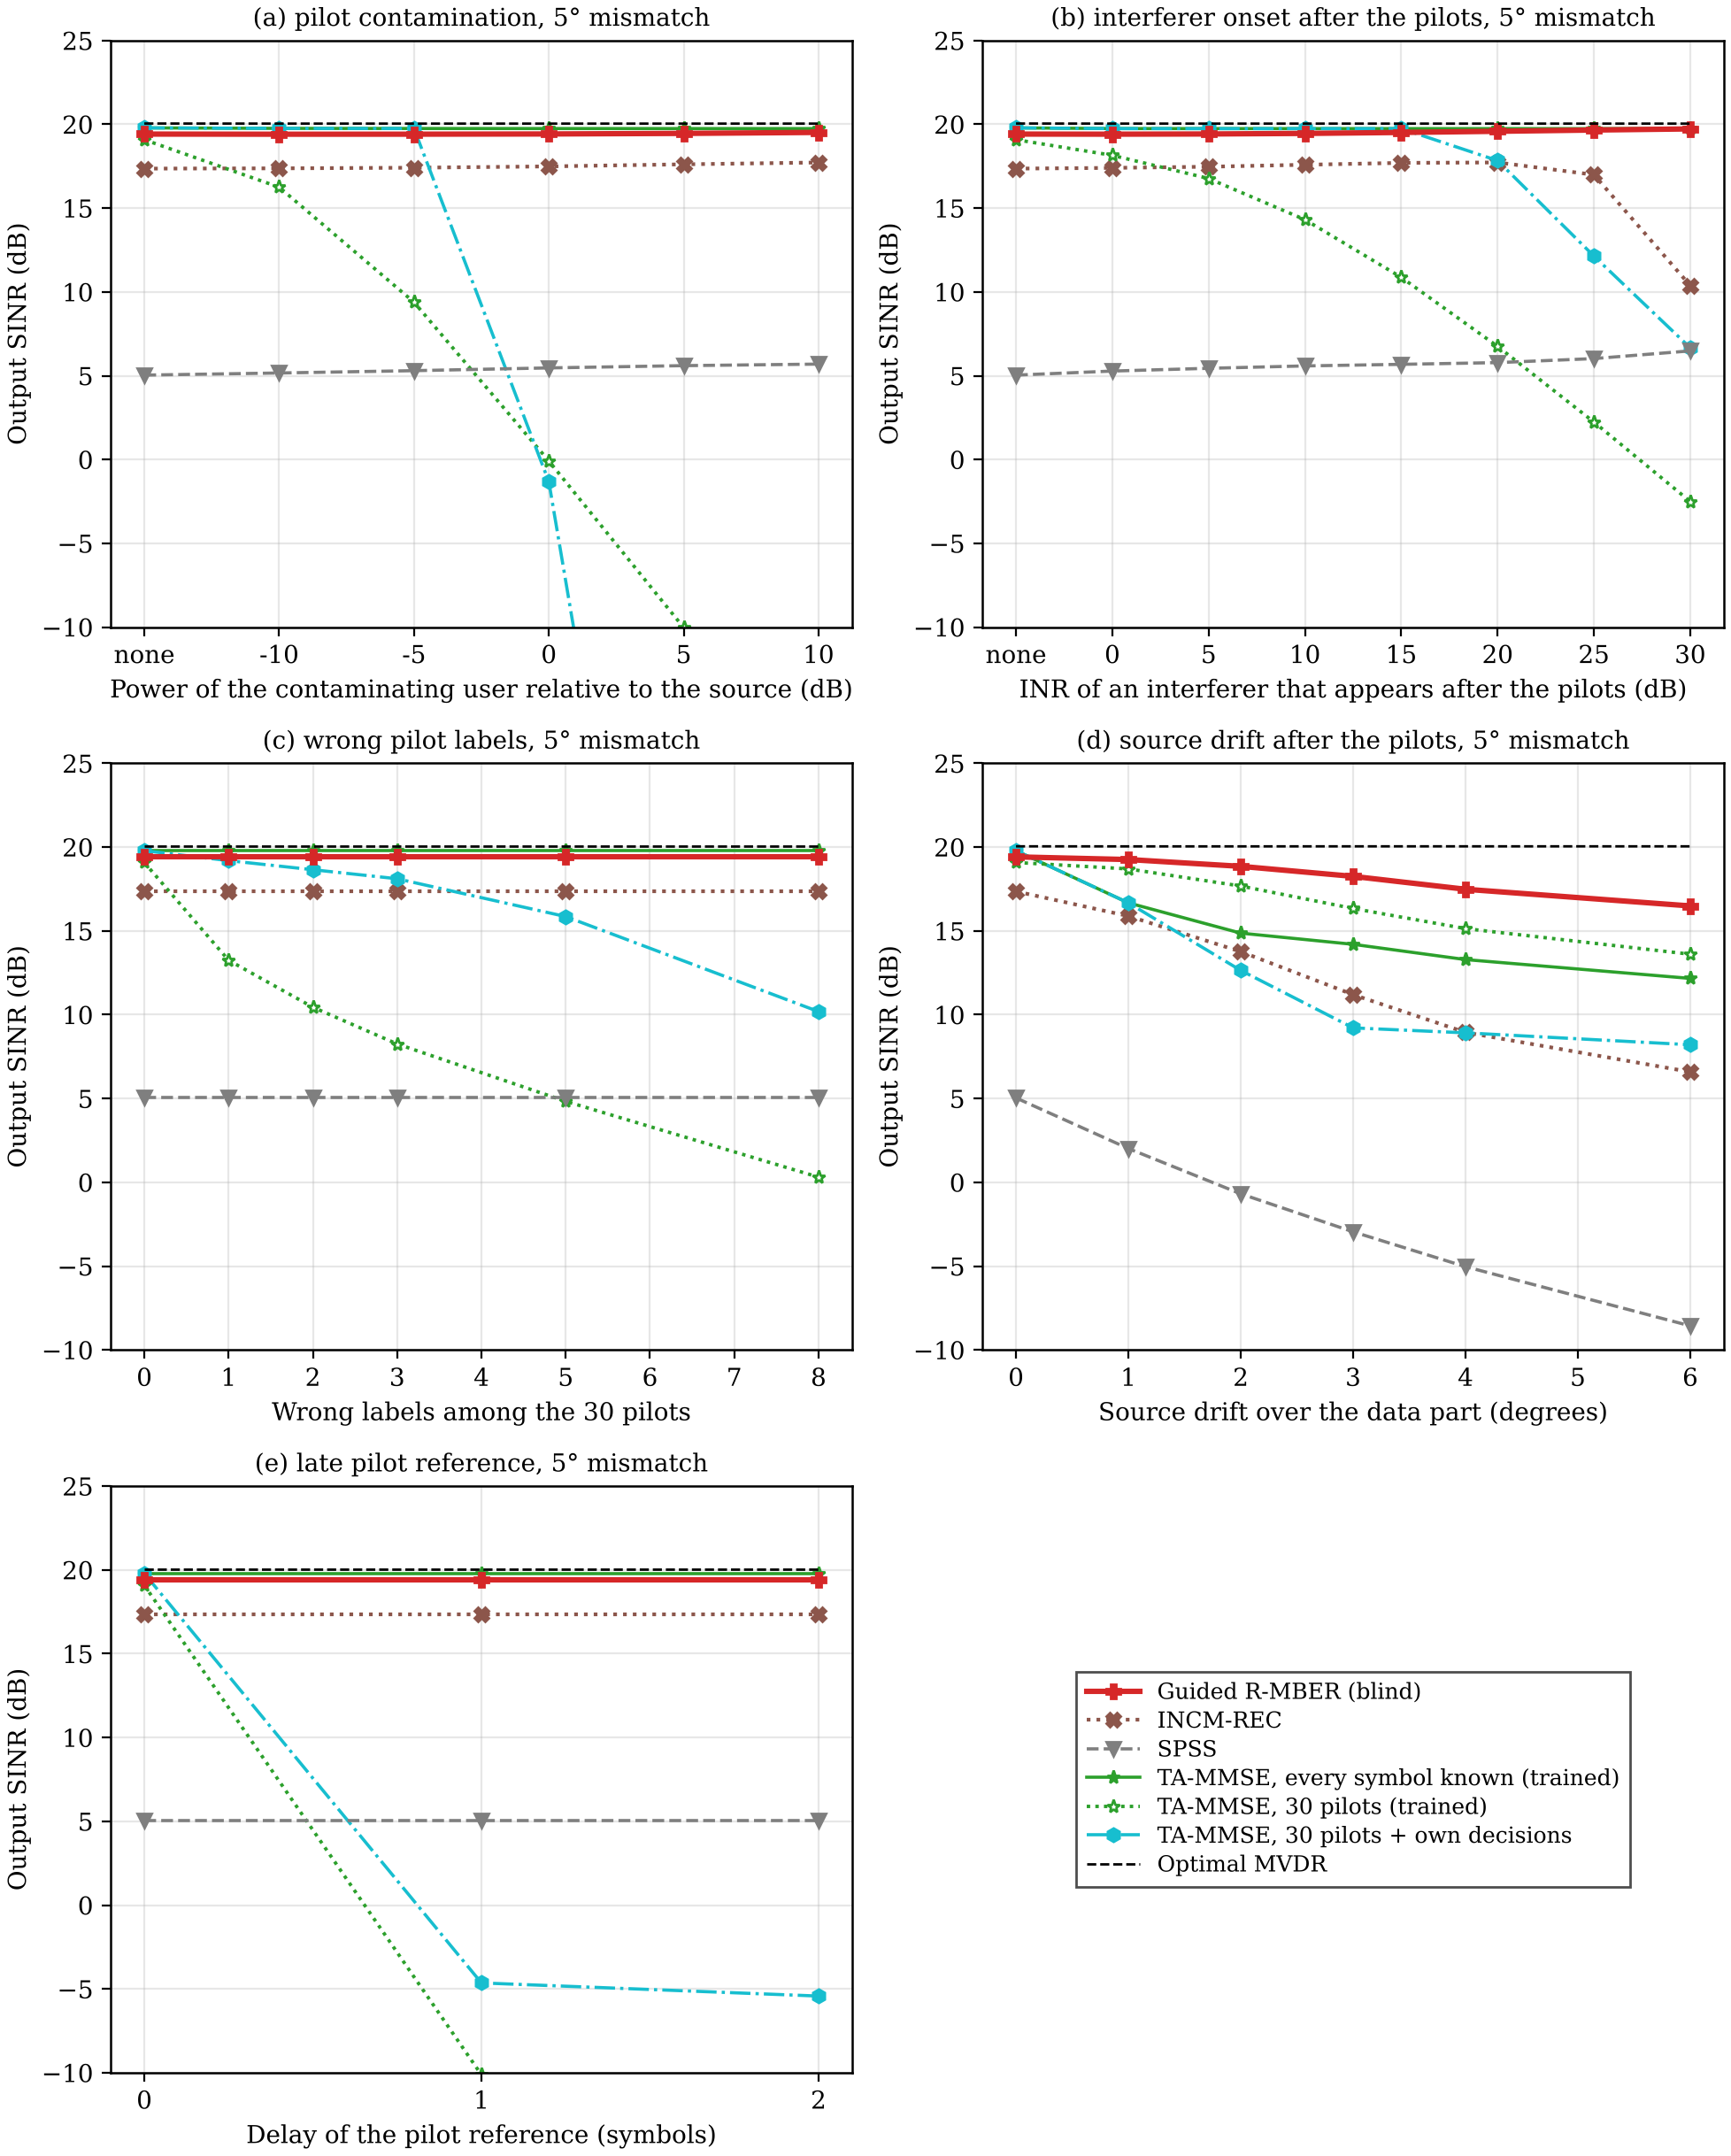

{
 "contam": {
  "values": [
   "None",
   "-10.0",
   "-5.0",
   "0.0",
   "5.0",
   "10.0"
  ],
  "guided R-MBER": [
   19.42,
   19.41,
   19.41,
   19.42,
   19.46,
   19.52
  ],
  "INCM-REC": [
   17.36,
   17.37,
   17.41,
   17.49,
   17.61,
   17.72
  ],
  "TA-MMSE, 30 pilots": [
   19.08,
   16.25,
   9.39,
   -0.09,
   -10.03,
   -20.07
  ],
  "TA-MMSE, 30 pilots + own decisions": [
   19.79,
   19.76,
   19.75,
   -1.32,
   -48.7,
   -54.13
  ],
  "TA-MMSE, every symbol known": [
   19.79,
   19.76,
   19.75,
   19.75,
   19.75,
   19.75
  ],
  "trained R-MBER, 30 pilots": [
   1.94,
   2.01,
   1.54,
   -0.97,
   -6.48,
   -12.66
  ],
  "optimum": [
   20.05,
   20.04,
   20.04,
   20.04,
   20.04,
   20.04
  ],
  "SPSS": [
   5.04,
   5.16,
   5.3,
   5.47,
   5.6,
   5.69
  ],
  "failed, guided R-MBER": [
   0,
   0,
   0,
   0,
   0,
   0
  ],
  "failed, TA-MMSE 30 pilots": [
   0,
   16,
   20,
   20,
   20,
   20
  ]
 },
 "onset": {
  "values": [
   "None",
   "0.0",
 

In [12]:
fig_4_10()
show('Figure 4.10')

## Figure 4.11: BER step under local scattering

Two local rays at +4° and −3° with growing amplitude, or at ±d with amplitude 0.4; output SINR at 5 dB and counted BER on 50 000 held-out symbols at −10 dB.

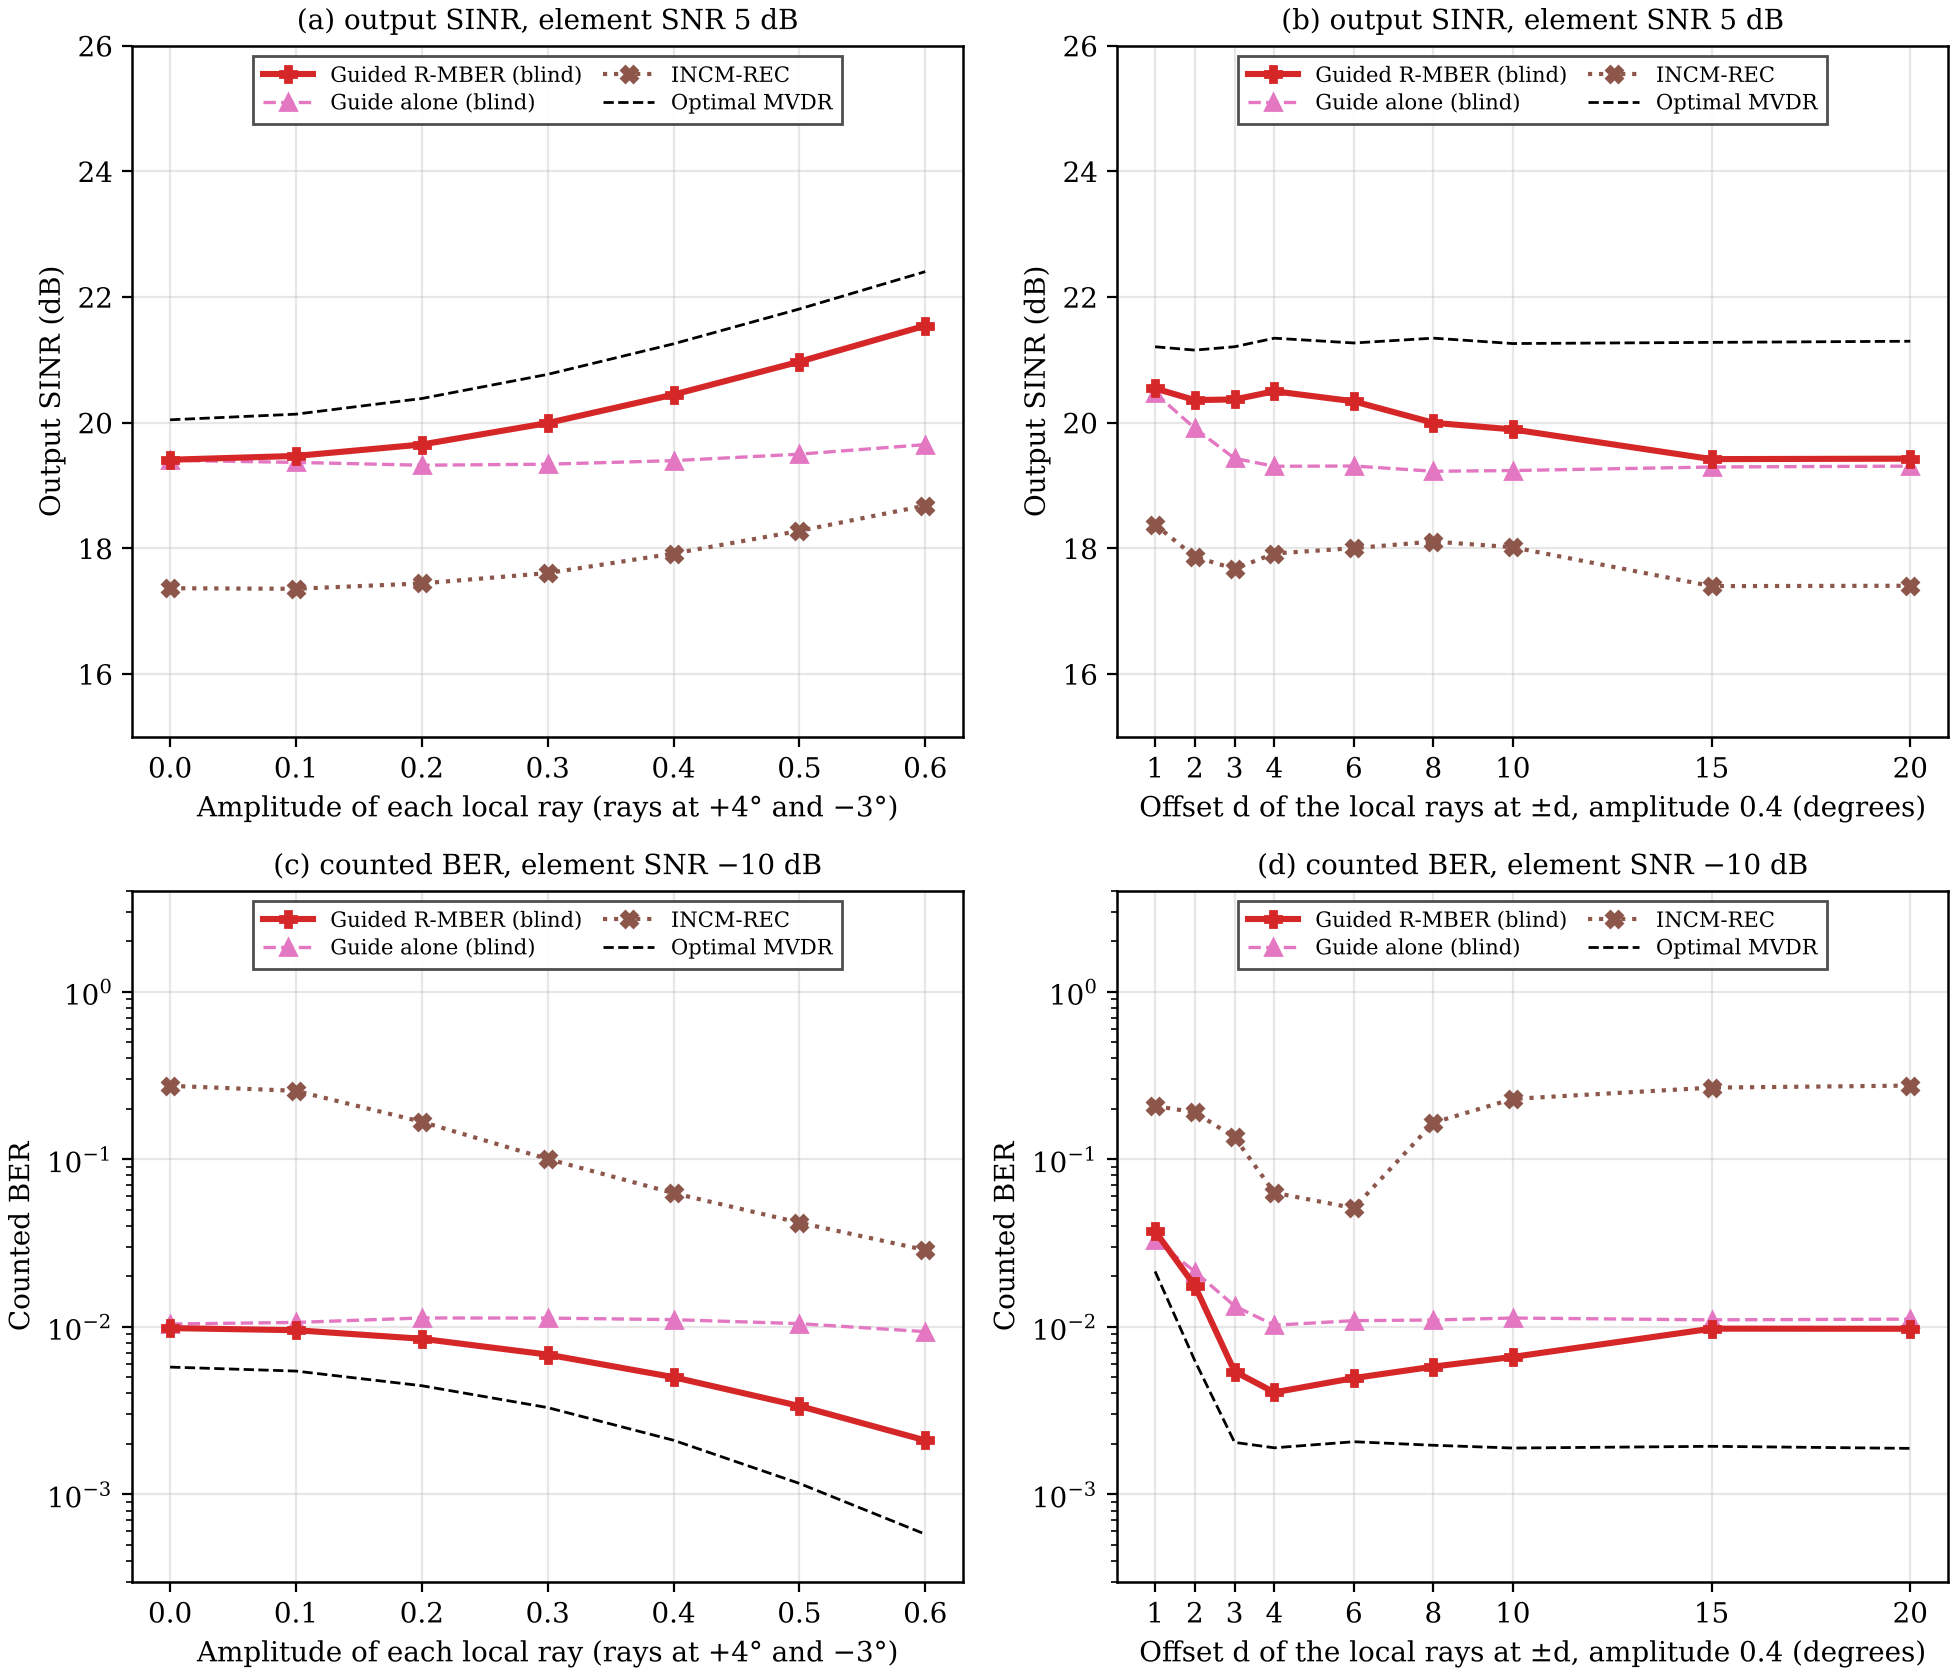

{
 "amp": {
  "x": [
   0.0,
   0.1,
   0.2,
   0.3,
   0.4,
   0.5,
   0.6
  ],
  "SINR guide alone": [
   19.4,
   19.37,
   19.32,
   19.34,
   19.4,
   19.5,
   19.65
  ],
  "SINR guided R-MBER": [
   19.41,
   19.47,
   19.65,
   20.0,
   20.45,
   20.97,
   21.54
  ],
  "SINR INCM-REC": [
   17.37,
   17.36,
   17.44,
   17.61,
   17.92,
   18.28,
   18.68
  ],
  "SINR optimum": [
   20.05,
   20.14,
   20.39,
   20.77,
   21.26,
   21.81,
   22.41
  ],
  "gain of the BER step (dB)": [
   0.01,
   0.1,
   0.33,
   0.66,
   1.05,
   1.47,
   1.89
  ],
  "counted BER guide alone": [
   0.010382,
   0.010612,
   0.011282,
   0.011265,
   0.011022,
   0.010432,
   0.009351
  ],
  "counted BER guided R-MBER": [
   0.009816,
   0.009531999999999999,
   0.008475000000000002,
   0.006820999999999999,
   0.004999999999999999,
   0.003365,
   0.002097
  ],
  "failed, guide alone": [
   0,
   0,
   0,
   0,
   2,
   6,
   8
  ],
  "failed, guided R-MBER": [
   0,
   0,
   0,
   0,
   0,
   

In [13]:
fig_4_11()
show('Figure 4.11')

## Numbers quoted in the text

Bandwidth floor and floor coefficient (Section 4.3.1), Dykstra sweeps, steering-vector distances and radius perturbation (Section 4.5), WC-MVDR/EigDec coverage and the two realization sets (Section 4.7.1), the gain of the BER step in the eight cases (Section 4.7.3), the held-out BER check (Section 4.7.5), TA-MMSE from 30 pilots (Section 4.7.8), the direction-only BER step (Section 4.7.9), and the constraint-based baselines with and without phase recovery and half-spaces (Section 4.7.10).

In [14]:
text_numbers()
T = RESULTS['Text']
for k in ('floor_c', 'dykstra', 'distances', 'incm_sets', 'radius', 'ta_loading', 'spss_sinc', 'WC-MVDR/EigDec coverage (deg)',
          'BER step gain in the eight cases', 'bandwidth floor and held-out BER', 'direction-only BER step', 'TA-MMSE, 30 pilots (mean SINR, dB)'):
    print(k, json.dumps(T.get(k), ensure_ascii=False)[:1500])

floor_c {"0.3": 14.62436024950981, "0.5": 16.682205664926574, "0.7": 15.182362678887559}
dykstra {"projections": 750, "median": 5.0, "max": 9, "cap_share": 0.0, "violation": 1.8394175071989594e-12}
distances {"16": {"distance": 1.8962116225893084, "limit": 3.6666666666666665}, "32": {"distance": 5.192557194037426, "limit": 5.3235209161590475}, "64": {"distance": 11.79688757140887, "limit": 7.666666666666667}}
incm_sets {"cases": 5.393706060594193, "sweep": 6.422924120932917, "se_units": 1.6863990205244592}
radius {"largest_change_db": 0.5269592529292115}
ta_loading {"0.1": 19.240864827948137, "0.3": 19.485814862011967, "1.0": 19.77437797348356, "3.0": 19.901631751552785, "10.0": 19.85881369715559}
spss_sinc {"0": [18.565635297438114, 18.701052746823827], "2": [16.837397695940155, 16.851887761839485]}
WC-MVDR/EigDec coverage (deg) {"8": 8.202, "16": 4.072, "32": 2.033, "64": 1.016}
BER step gain in the eight cases {"2 pt": [0.007113905928907904, -0.0012056484487795588, 0.015433460306595

In [15]:
for m, s in [('phase_recovery', 'all'), ('no_constraints', 'all'), ('blind_no_halfspaces', 'all'), ('text_checks', 'wc_solver')]:
    print(f'===== {m} {s}'); print(S.log_text(DATA, m, s))

===== phase_recovery all

M=32, point source, 20 trials; half-power beamwidth 3.2 deg, first null 3.6 deg
mismatch (deg)                0.0    0.5    1.0    1.5    2.0    2.5    3.0    5.0    7.0    9.0   11.0
Trained R-MBER               17.3   17.0   16.9   16.7   16.7   16.9   16.9   16.8   16.5   16.7   16.6
Blind, no phase rec.         17.3   17.0   16.8    5.2   -5.8   -4.8   -7.3   -7.1  -12.5  -11.2  -14.1
Blind, phase rec.            17.3   17.1   16.8   16.7   16.8   11.4   -4.1    6.0  -12.7   -9.9  -14.0
early dec. err, no phase     0.00   0.00   0.01   0.13   0.29   0.28   0.30   0.28   0.33   0.31   0.33
early dec. err, phase        0.00   0.00   0.00   0.01   0.05   0.11   0.28   0.15   0.38   0.35   0.34
failed runs, no phase        0.00   0.00   0.00   0.65   1.00   0.95   1.00   0.95   1.00   1.00   1.00
failed runs, phase           0.00   0.00   0.00   0.00   0.00   0.35   0.85   0.55   1.00   0.95   1.00

M=16, point source, 20 trials; half-power beamwidth 6.3 deg, 

In [16]:
print('results summary:', write_summary())

results summary: /home/claude/robust-adaptive-beamforming-book/chapter-04/figures/results_summary.json
